# Session 6 : les exercices et le TP expliqués pas à pas

**Mieux entraîner un réseau** (MSA-DATB09-03, Neural Networks & Deep Learning Foundations) : régularisation, normalisation, optimiseurs, et comment lire une courbe d'entraînement.

Ce notebook contient **toutes les réponses** de la session 6, dans cet ordre :

1. **Partie 1 : les 5 exercices du cours** (slides 8, 12, 16, 21 et 25), calculés à la main puis vérifiés en Python ;
2. **Partie 2 : le TP06** (`TP06_better_training.ipynb`), ses 23 exercices complétés, avec les `assert` d'origine qui doivent afficher `Exercise validated!`.

| Bloc | Sujet | Slides | L'outil en une phrase |
|---|---|---|---|
| Exercice du cours 1 | weight decay | 6 à 8 | un élastique qui ramène chaque poids vers 0 |
| Exercice du cours 2 | dropout | 9 à 12 | éteindre des neurones au hasard pour qu'aucun ne soit indispensable |
| Exercice du cours 3 | batch normalisation | 14 à 17 | remettre chaque neurone à la même échelle à chaque batch |
| Exercice du cours 4 | SGD, momentum, Adam | 18 à 21 | de meilleurs pas que la descente de gradient simple |
| Exercice du cours 5 | diagnostiquer 4 entraînements | 22 à 25 | lire les courbes comme un médecin lit une radio |
| TP partie A (ex. 1 à 3) | provoquer le surapprentissage | 4 et 5 | |
| TP partie B (ex. 4 à 11) | weight decay, dropout, early stopping | 6 à 13 | **livrable** : le tableau comparatif |
| TP partie C (ex. 12 à 14) | batch norm à la main | 14 et 15 | |
| TP partie D (ex. 15 à 18) | momentum et Adam à la main, schedule | 18 à 22 | |
| TP partie E (ex. 19 à 22) | le docteur de l'entraînement | 23 et 24 | |
| TP bonus (ex. 23) | ton meilleur modèle | tout | |

Pour ne pas confondre : « **Exercice du cours n** » renvoie aux slides, « **TP · Exercice n** » au notebook TP06.

**Comment le lire.** Chaque exercice suit le même plan :

1. 📖 **Le cours** : l'idée, la formule, et d'où elle vient (avec une image pour s'en souvenir).
2. ✍️ **Le calcul à la main** (exercices du cours) ou 🧩 **le code ligne par ligne** (TP) : ce que fait chaque ligne, et pourquoi.
3. 💻 **Le code** : pour le TP, la solution entre `### START CODE HERE ###` et `### END CODE HERE ###`, suivie des `assert` d'origine.
4. 💡 **Ce qu'on observe** : comment lire le résultat.

**Pour l'exécuter** : Google Colab (Fichier > Importer un notebook) ou en local avec `torch`, `torchvision`, `pandas` et `matplotlib`. Le TP entraîne de petits réseaux sur 2 000 images : quelques minutes sur un CPU. Exécute les cellules **dans l'ordre** (Shift + Entrée). Les chiffres cités dans le texte viennent de notre exécution ; chez toi, ils peuvent varier un peu.

## Le problème du jour en une image (slides 4 et 5)

À la session 5, on a appris à faire **apprendre** un réseau profond (ReLU, initialisation de He). Aujourd'hui, le problème inverse : il apprend **trop bien**.

Un réseau 784-512-512-10 (670 000 paramètres) entraîné sur seulement **2 000 images** de FashionMNIST :

- la loss d'entraînement descend presque à 0 (précision d'entraînement 99.8 %) ;
- la loss de validation est la meilleure vers l'époque 8, puis **remonte** (précision de validation bloquée vers 82 %).

Le réseau a **appris par cœur** ses 2 000 images, y compris leurs détails sans importance. C'est comme un étudiant qui apprend par cœur les corrigés des annales : 20/20 sur les annales, mais il est perdu face à un sujet nouveau. Pire, il devient **trop sûr de lui** sur les images qu'il n'a jamais vues : ses erreurs coûtent de plus en plus cher, d'où la loss de validation qui remonte.

**Le vocabulaire de la séance**

| Mot | Ce que ça veut dire |
|---|---|
| **surapprentissage** (overfitting, « grande variance ») | erreur d'entraînement faible, erreur de validation bien plus haute : le modèle colle au bruit de ses données |
| **sous-apprentissage** (underfitting, « grand biais ») | erreur d'entraînement elle-même élevée : modèle trop simple ou pas assez entraîné |
| **écart** (gap) | précision d'entraînement moins précision de validation : la mesure du surapprentissage |
| **régularisation** | tout ce qui empêche le réseau d'apprendre par cœur |
| $\lambda$ (lambda) | la force du weight decay |
| $p$ | la probabilité d'**éteindre** un neurone (dropout) |
| **checkpoint** | une sauvegarde des poids à un instant donné |
| $\gamma$, $\beta$ (batch norm) | les deux paramètres **appris** de la batch norm : une échelle et un décalage par neurone |
| $\beta$ (momentum) | la « mémoire » de la vitesse, en général 0.9. Attention : même lettre, autre sens que le $\beta$ de la batch norm |
| $m$, $s$ (Adam) | la moyenne des gradients et la moyenne de leurs carrés |
| **scheduler** | une règle qui fait varier le pas $\eta$ pendant l'entraînement |

**Les outils de la séance** (slide 5) :

| Outil | Idée |
|---|---|
| weight decay (L2) | garder les poids petits |
| dropout | ne dépendre d'aucun neurone en particulier |
| early stopping | s'arrêter à la meilleure époque de validation |
| batch norm | garder les entrées de chaque couche à la bonne échelle |
| momentum, Adam | de meilleurs pas que le SGD simple |

Le premier remède est toujours **plus de données**. Quand on ne peut pas, on **régularise**.

---
# 0. Mise en place : les imports, les données et les outils du TP

On exécute d'abord les deux cellules de départ du TP06 (imports et fonctions utilitaires), car les vérifications de la partie 1 s'en servent aussi.

| Import | À quoi il sert |
|---|---|
| `numpy` | de petits calculs (`np.argmin`...) |
| `pandas` | le tableau comparatif de la partie B |
| `matplotlib` | les courbes d'entraînement |
| `torch`, `torch.nn` | les réseaux ; `DataLoader` et `TensorDataset` servent les mini-batchs |
| `torchvision.datasets` | télécharge FashionMNIST |
| `copy` | `copy.deepcopy` fait une copie **indépendante** des poids (pour l'early stopping) |

Deux constantes : `EPOCHS = 30` pour les parties A et B (il faut du temps pour voir le surapprentissage) et `EPOCHS_SHORT = 10` pour les parties C, D et E.

In [1]:
import os
import copy
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: shorter trainings for a quick check
DATA_DIR = os.environ.get("DATA_DIR", "./data")
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)

EPOCHS = 15 if FAST_RUN else 30        # Parts A and B (we want to see overfitting)
EPOCHS_SHORT = 6 if FAST_RUN else 10   # Parts C, D, E
print("FAST_RUN:", FAST_RUN)

FAST_RUN: False


### Ce que prépare la cellule suivante (à exécuter telle quelle)

**Les données.** On prend **2 000 images d'entraînement** et **5 000 images de validation** dans FashionMNIST (sans recouvrement), aplaties en vecteurs de 784 pixels et standardisées avec la moyenne et l'écart-type des images d'entraînement (comme en session 5). 2 000 images, c'est **volontairement peu** : on veut provoquer le surapprentissage.

**Trois DataLoaders** :

- `train_loader` : batchs de 64, mélangés, pour **entraîner** ($2\,000 / 64 \approx 32$ pas par époque) ;
- `train_eval_loader` : les mêmes images d'entraînement, par batchs de 1000, pour **mesurer** la précision d'entraînement ;
- `val_loader` : les 5 000 images de validation.

**Les fonctions :**

| Fonction | Ce qu'elle fait |
|---|---|
| `train_one_epoch(model, loader, loss_fn, optimizer)` | une époque : pour chaque batch, les 5 lignes de la boucle (`zero_grad`, forward + loss, `backward`, `step`) |
| `evaluate(model, loader, loss_fn)` | renvoie `(loss moyenne, précision)` en mode évaluation, sans gradient |
| `record(history, model, optimizer)` | mesure le modèle sur l'entraînement **et** la validation, et ajoute les 5 valeurs à l'historique |
| `fit(model, optimizer, n_epochs, ...)` | entraîne `n_epochs` époques, renvoie l'**historique** : un dictionnaire de listes `"train_loss"`, `"train_acc"`, `"val_loss"`, `"val_acc"`, `"lr"` (une valeur par époque) |
| `plot_history(history)`, `plot_compare(histories, key)` | les graphiques |
| `count_parameters(model)` | le nombre de paramètres |

Deux détails importants de `fit` :

- `torch.manual_seed(1)` au début : **le même ordre des mini-batchs pour toutes les expériences**. Quand on compare deux réglages, la seule différence est le réglage lui-même.
- La précision d'entraînement est mesurée **après** chaque époque, en mode évaluation, sur toutes les images d'entraînement. Entraînement et validation sont donc mesurés **de la même façon** (sans dropout par exemple) : l'écart entre les deux est honnête.

In [2]:
full = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
X_all = full.data.float().div(255).reshape(-1, 784)        # (60000, 784), pixels in [0, 1]
y_all = full.targets                                        # (60000,), labels 0 to 9
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
train_idx, val_idx = perm[:2000], perm[-5000:]
MEAN, STD = X_all[train_idx].mean(), X_all[train_idx].std()    # statistics of the training images only
X_train, y_train = (X_all[train_idx] - MEAN) / STD, y_all[train_idx]
X_val, y_val = (X_all[val_idx] - MEAN) / STD, y_all[val_idx]

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=1000)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
loss_fn = nn.CrossEntropyLoss()
print("train", tuple(X_train.shape), "validation", tuple(X_val.shape))


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        n += len(yb)
    return total / n


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def new_history():
    return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}


def record(history, model, optimizer):
    """Measure the model on the training and validation sets and append the results to the history."""
    tl, ta = evaluate(model, train_eval_loader, loss_fn)
    vl, va = evaluate(model, val_loader, loss_fn)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl); history["val_acc"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])


def fit(model, optimizer, n_epochs, train_epoch_fn=train_one_epoch, scheduler=None, verbose=False):
    torch.manual_seed(1)                       # same order of the mini-batches for every run
    history = new_history()
    for epoch in range(n_epochs):
        train_epoch_fn(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        if scheduler is not None:
            scheduler.step()
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {history['train_loss'][-1]:.3f}  "
                  f"val loss {history['val_loss'][-1]:.3f}  val acc {history['val_acc'][-1]:.3f}")
    return history


def plot_history(history, title=""):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


def plot_compare(histories, key="val_loss"):
    plt.figure(figsize=(7, 3.5))
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("epoch"); plt.ylabel(key); plt.legend()
    plt.show()


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

train (2000, 784) validation (5000, 784)


---
# Partie 1 : les exercices du cours

---
## Exercice du cours 1 : une mise à jour avec weight decay (slide 8)

> **Énoncé** : une couche a deux poids $w = (2, -1)$. La backpropagation donne $\partial J/\partial w = (0.5, -0.5)$. On utilise $\eta = 0.1$.
>
> 1. Calculer les nouveaux poids **sans** régularisation.
> 2. Calculer les nouveaux poids **avec** weight decay $\lambda = 0.5$. Quel est le facteur de décroissance $1 - \eta\lambda$ ?
> 3. Calculer la pénalité $\frac{\lambda}{2}\lVert w \rVert^2$ au départ.
> 4. Si le gradient des données était nul, après combien de pas un poids serait-il divisé par deux ?

### 📖 Le cours : la régularisation L2 (slides 6 et 7)

**L'idée.** On ajoute au coût $J$ (la loss moyenne sur les données) un terme qui **pénalise les grands poids** :

$$J_\text{reg}(W) = J(W) + \frac{\lambda}{2}\lVert W \rVert^2, \qquad \lVert W \rVert^2 = \sum_l \sum_{j,k} \big(W^{[l]}_{jk}\big)^2$$

- $\lambda \ge 0$ règle la force (valeurs typiques de $10^{-5}$ à $10^{-2}$). Les **biais** ne sont en général pas pénalisés.
- **Pourquoi ça aide** : un réseau aux petits poids calcule une fonction plus **lisse**, qui ne peut pas suivre chaque point bruité des données d'entraînement. Pour coller parfaitement à 2 000 images, il faudrait des poids énormes et très précis : la pénalité les rend trop « chers ».

**Le gradient du terme ajouté**, poids par poids (le $\frac{1}{2}$ est là pour simplifier la dérivée) :

$$\frac{\partial}{\partial w}\Big(\frac{\lambda}{2}w^2\Big) = \lambda\,w \qquad\Longrightarrow\qquad \frac{\partial J_\text{reg}}{\partial w} = \frac{\partial J}{\partial w} + \lambda\,w$$

**La mise à jour devient** :

$$w \leftarrow w - \eta\Big(\frac{\partial J}{\partial w} + \lambda w\Big) = \underbrace{(1 - \eta\lambda)}_{\text{un peu moins que 1}}\,w \;-\; \eta\,\frac{\partial J}{\partial w}$$

À chaque pas, le poids est d'abord **multiplié par $1 - \eta\lambda$** : il « décroît » vers 0 (d'où le nom **weight decay**), puis on fait le pas habituel. Image : chaque poids est attaché à 0 par un **élastique**. Un poids dont les données n'ont pas besoin finit à 0 ; un poids utile est retenu par son gradient.

En PyTorch : `torch.optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-3)` ajoute $\lambda w$ à chaque gradient ; `torch.optim.AdamW(..., weight_decay=1e-2)` est la version « découplée » adaptée à Adam.

### ✍️ Question 1 : sans régularisation

La descente de gradient habituelle, $w \leftarrow w - \eta\,\dfrac{\partial J}{\partial w}$, composante par composante :

| | $w$ | $\partial J / \partial w$ | $\eta \times \partial J / \partial w$ | nouveau $w$ |
|---|---|---|---|---|
| $w_1$ | 2 | 0.5 | $0.1 \times 0.5 = 0.05$ | $2 - 0.05 = \mathbf{1.95}$ |
| $w_2$ | -1 | -0.5 | $0.1 \times (-0.5) = -0.05$ | $-1 - (-0.05) = \mathbf{-0.95}$ |

Nouveaux poids : $w = (1.95,\ -0.95)$.

### ✍️ Question 2 : avec weight decay $\lambda = 0.5$

**Le facteur de décroissance** : $1 - \eta\lambda = 1 - 0.1 \times 0.5 = 1 - 0.05 = \mathbf{0.95}$. À chaque pas, chaque poids perd 5 % de sa valeur avant le pas habituel.

**Méthode 1, avec le facteur** : $w \leftarrow 0.95\,w - \eta\,\dfrac{\partial J}{\partial w}$

- $w_1 = 0.95 \times 2 - 0.05 = 1.90 - 0.05 = \mathbf{1.85}$
- $w_2 = 0.95 \times (-1) - (-0.05) = -0.95 + 0.05 = \mathbf{-0.90}$

**Méthode 2, avec le gradient total** : $\dfrac{\partial J_\text{reg}}{\partial w} = \dfrac{\partial J}{\partial w} + \lambda w = (0.5 + 0.5 \times 2,\ -0.5 + 0.5 \times (-1)) = (1.5,\ -1.0)$, puis $w - 0.1 \times (1.5, -1.0) = (2 - 0.15,\ -1 + 0.1) = (1.85,\ -0.90)$. Même résultat.

**Lecture** : par rapport à la question 1, $w_1$ a perdu 0.10 de plus ($1.95 \to 1.85$) et $w_2$ s'est rapproché de 0 de 0.05 de plus ($-0.95 \to -0.90$). L'élastique tire **proportionnellement à la taille du poids** : le grand poids (2) est tiré deux fois plus fort que le petit (-1).

### ✍️ Question 3 : la pénalité au départ

$$\frac{\lambda}{2}\lVert w \rVert^2 = \frac{0.5}{2}\big(2^2 + (-1)^2\big) = 0.25 \times (4 + 1) = 0.25 \times 5 = \mathbf{1.25}$$

C'est ce qu'on ajoute au coût $J$ : plus les poids sont grands, plus ce terme coûte cher.

### ✍️ Question 4 : la demi-vie d'un poids inutile

Si $\partial J / \partial w = 0$, il ne reste que la décroissance : $w \leftarrow 0.95\,w$ à chaque pas. Après $k$ pas :

$$w_k = 0.95^k\,w_0$$

Le poids est divisé par deux quand $0.95^k = 0.5$, c'est-à-dire (en prenant le logarithme des deux côtés) :

$$k = \frac{\ln 0.5}{\ln 0.95} = \frac{-0.693}{-0.0513} \approx 13.5$$

Donc **après 14 pas** (après 13 pas il reste 51.3 % du poids, après 14 pas 48.8 %).

**Règle pratique** : comme $\ln(1 - x) \approx -x$ pour $x$ petit, $k \approx \dfrac{\ln 2}{\eta\lambda} = \dfrac{0.693}{0.05} \approx 14$. Plus $\eta\lambda$ est grand, plus les poids inutiles disparaissent vite.

### 💻 Vérification en Python

Question 1, sans régularisation : [1.95, -0.95]
Question 2, facteur 1 - eta*lambda = 0.95
            avec weight decay       : [1.85, -0.9]
Question 3, pénalité = 1.25
            torch.optim.SGD(weight_decay=0.5) : [1.85, -0.9]
Question 4 : poids divisé par 2 après 14 pas (ln 2 / (eta lambda) = 13.9)


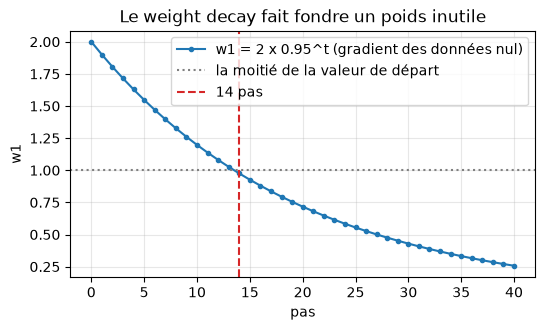

In [3]:
w = torch.tensor([2.0, -1.0])
g = torch.tensor([0.5, -0.5])
eta, lam = 0.1, 0.5

print("Question 1, sans régularisation :", [round(v, 4) for v in (w - eta * g).tolist()])
print(f"Question 2, facteur 1 - eta*lambda = {1 - eta * lam}")
print("            avec weight decay       :", [round(v, 4) for v in (w - eta * (g + lam * w)).tolist()])
print(f"Question 3, pénalité = {(lam / 2 * (w ** 2).sum()).item()}")

# PyTorch fait exactement la même chose avec weight_decay=0.5
w_t = w.clone().requires_grad_(True)
opt = torch.optim.SGD([w_t], lr=eta, weight_decay=lam)
w_t.grad = g.clone()          # on donne le gradient des données à la main
opt.step()
print("            torch.optim.SGD(weight_decay=0.5) :", [round(v, 4) for v in w_t.detach().tolist()])

# Question 4 : on compte les pas jusqu'à la moitié
valeur, k = 1.0, 0
while valeur > 0.5:
    valeur *= 1 - eta * lam
    k += 1
print(f"Question 4 : poids divisé par 2 après {k} pas (ln 2 / (eta lambda) = {math.log(2) / (eta * lam):.1f})")

pas = range(0, 41)
plt.figure(figsize=(6, 3.2))
plt.plot(pas, [2 * 0.95 ** t for t in pas], "o-", ms=3, label="w1 = 2 x 0.95^t (gradient des données nul)")
plt.axhline(1, color="gray", ls=":", label="la moitié de la valeur de départ")
plt.axvline(k, color="C3", ls="--", label=f"{k} pas")
plt.xlabel("pas"); plt.ylabel("w1"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Le weight decay fait fondre un poids inutile")
plt.show()

> ✅ **À retenir (exercice du cours 1)**
>
> - Weight decay = ajouter $\frac{\lambda}{2}\lVert W\rVert^2$ au coût, donc $\lambda w$ au gradient.
> - Mise à jour : $w \leftarrow (1 - \eta\lambda)\,w - \eta\,\partial J/\partial w$. Le poids est d'abord rétréci, puis on fait le pas habituel.
> - Un poids inutile est divisé par 2 en environ $\ln 2 / (\eta\lambda)$ pas.

---
## Exercice du cours 2 : appliquer un masque de dropout (slide 12)

> **Énoncé** : une couche cachée sort $a = (2, 1, 4, 3)$. Dropout avec $p = 0.5$ ; le masque tiré pour ce pas est $m = (1, 0, 1, 0)$.
>
> 1. Calculer $\tilde a$ en mode entraînement (dropout inversé).
> 2. Comparer la somme de $\tilde a$ à la somme de $a$. Est-ce un problème ?
> 3. Quelle est l'espérance de $\tilde a_1$ sur tous les masques possibles ?
> 4. Que renvoie la couche en mode évaluation ?

### 📖 Le cours : le dropout (slides 9 à 11)

**L'idée** (Srivastava, Hinton et al., 2014). À **chaque pas d'entraînement**, chaque neurone caché est **éteint** (sa sortie mise à 0) avec une probabilité $p$, indépendamment des autres. Chaque pas entraîne donc un réseau « aminci » différent. Valeurs typiques : $p$ entre 0.1 et 0.5.

Image : une équipe où, chaque jour, des membres tirés au sort sont absents. Personne ne peut compter sur **un** collègue précis : chacun doit savoir se débrouiller, et le savoir se retrouve en plusieurs exemplaires. Le réseau apprend des caractéristiques **redondantes**, plus robustes, au lieu de combinaisons fragiles qui collent aux images d'entraînement.

**Au test** : pas de dropout, on utilise le réseau complet.

**Le dropout « inversé » : pourquoi diviser par $1 - p$.** On tire un masque $m_i \in \{0, 1\}$ avec $P(m_i = 1) = 1 - p$ (garder), puis :

$$\tilde a_i = \frac{m_i\,a_i}{1 - p} \ \ \text{(entraînement)}, \qquad \tilde a_i = a_i \ \ \text{(évaluation)}$$

En moyenne pendant l'entraînement :

$$\mathbb{E}[\tilde a_i] = \frac{a_i}{1 - p}\,\mathbb{E}[m_i] = \frac{a_i}{1 - p}\big(1 \times (1 - p) + 0 \times p\big) = a_i$$

La couche suivante reçoit donc **en moyenne le même signal** en entraînement et en test : rien à changer au test. Sans le $1/(1 - p)$, elle verrait au test des entrées environ $1/(1 - p)$ fois plus grandes qu'à l'entraînement (2 fois plus grandes avec $p = 0.5$).

**En PyTorch** : `nn.Dropout(p=0.5)` (`p` = probabilité d'**éteindre**). En mode `train()` il applique le masque et multiplie par $1/(1 - p)$ ; en mode `eval()` il ne fait rien.

⚠️ **Le bug classique** : oublier `model.eval()` avant d'évaluer (les prédictions deviennent aléatoires, la précision chute), ou oublier `model.train()` après (le dropout est silencieusement désactivé pour la suite de l'entraînement).

### ✍️ Question 1 : $\tilde a$ en mode entraînement

$1 - p = 0.5$, donc on divise par 0.5, c'est-à-dire qu'on **multiplie par 2** les valeurs gardées :

| neurone $i$ | $a_i$ | $m_i$ | $m_i\,a_i$ | $\tilde a_i = m_i a_i / 0.5$ |
|---|---|---|---|---|
| 1 | 2 | 1 (gardé) | 2 | **4** |
| 2 | 1 | 0 (éteint) | 0 | **0** |
| 3 | 4 | 1 (gardé) | 4 | **8** |
| 4 | 3 | 0 (éteint) | 0 | **0** |

$\tilde a = (4,\ 0,\ 8,\ 0)$.

### ✍️ Question 2 : la somme a changé

$\sum \tilde a_i = 4 + 0 + 8 + 0 = 12$, alors que $\sum a_i = 2 + 1 + 4 + 3 = 10$.

**Ce n'est pas un problème.** L'égalité n'est vraie qu'**en moyenne** (question 3), pas pour chaque masque. Avec le masque opposé $(0, 1, 0, 1)$, on aurait $\tilde a = (0, 2, 0, 6)$, de somme 8. En moyenne sur tous les masques, la somme vaut bien 10. Ce bruit d'un pas à l'autre est **voulu** : c'est justement lui qui empêche le réseau de compter sur un neurone précis. La couche suivante reçoit le bon signal en moyenne.

### ✍️ Question 3 : l'espérance de $\tilde a_1$

$\tilde a_1$ ne peut prendre que deux valeurs :

- $m_1 = 1$ (probabilité $1 - p = 0.5$) : $\tilde a_1 = 2 / 0.5 = 4$ ;
- $m_1 = 0$ (probabilité $p = 0.5$) : $\tilde a_1 = 0$.

$$\mathbb{E}[\tilde a_1] = 4 \times 0.5 + 0 \times 0.5 = \mathbf{2} = a_1$$

C'est exactement la formule du cours : diviser par $1 - p$ compense les fois où le neurone est éteint.

### ✍️ Question 4 : en mode évaluation

Pas de masque, pas de division : la couche est l'**identité**, elle renvoie $a = (2, 1, 4, 3)$ tel quel. Pas besoin de corriger quoi que ce soit au test, grâce au $1/(1 - p)$ de l'entraînement.

### 💻 Vérification en Python

On calcule $\tilde a$, puis on fait la moyenne sur **les 16 masques possibles** (avec $p = 0.5$, ils sont tous équiprobables), et on reproduit l'exemple de `nn.Dropout` de la slide 11.

In [4]:
import itertools

a = torch.tensor([2.0, 1.0, 4.0, 3.0])
p = 0.5
m = torch.tensor([1.0, 0.0, 1.0, 0.0])
a_tilde = m * a / (1 - p)
print("Question 1 : a_tilde =", a_tilde.tolist())
print(f"Question 2 : somme de a_tilde = {a_tilde.sum().item()}, somme de a = {a.sum().item()}")

# Question 3 : la moyenne sur les 16 masques possibles (tous de probabilité 0.5^4)
masques = torch.tensor(list(itertools.product([0.0, 1.0], repeat=4)))     # (16, 4)
toutes = masques * a / (1 - p)                                              # les 16 a_tilde possibles
print("Question 3 : moyenne de a_tilde sur les 16 masques =", toutes.mean(dim=0).tolist(), "= a")
print("             moyenne des 16 sommes =", toutes.sum(dim=1).mean().item())

# Question 4 et slide 11 : nn.Dropout en mode train puis eval
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("\nnn.Dropout, mode train :", drop(torch.ones(8)).tolist(), " (valeurs gardées x 1/(1-p) = 2)")
drop.eval()
print("nn.Dropout, mode eval  :", drop(a).tolist(), " (identité)")

Question 1 : a_tilde = [4.0, 0.0, 8.0, 0.0]
Question 2 : somme de a_tilde = 12.0, somme de a = 10.0
Question 3 : moyenne de a_tilde sur les 16 masques = [2.0, 1.0, 4.0, 3.0] = a
             moyenne des 16 sommes = 10.0

nn.Dropout, mode train : [0.0, 0.0, 2.0, 0.0, 0.0, 0.0, 2.0, 2.0]  (valeurs gardées x 1/(1-p) = 2)
nn.Dropout, mode eval  : [2.0, 1.0, 4.0, 3.0]  (identité)


> ✅ **À retenir (exercice du cours 2)**
>
> - Dropout : éteindre chaque neurone avec probabilité $p$ **à l'entraînement**, et multiplier les survivants par $1/(1 - p)$.
> - Le signal est conservé **en moyenne** ; d'un pas à l'autre il varie, et c'est voulu.
> - En évaluation : l'identité. D'où l'importance de `model.train()` et `model.eval()`.

---
## Exercice du cours 3 : batch norm sur un batch de 4 nombres (slide 16)

> **Énoncé** : un neurone, un batch de 4 pré-activations $z = (1, 3, 3, 9)$. Paramètres appris $\gamma = 2$, $\beta = 0.5$. On néglige $\varepsilon$.
>
> 1. Calculer $\mu_B$ et $\sigma_B^2$.
> 2. Calculer les valeurs normalisées $\hat z$. Vérifier que leur moyenne est 0.
> 3. Calculer les sorties $y = \gamma \hat z + \beta$.
> 4. La moyenne glissante part de 0 (momentum 0.1). Que vaut-elle après ce batch ?

### 📖 Le cours : la normalisation par batch (slides 14 et 15)

**Le problème.** En session 5, on a vu que la taille du signal peut fondre ou exploser de couche en couche, et on l'a réglé avec la bonne initialisation. Mais pendant l'entraînement, les poids bougent, et la distribution des entrées de chaque couche change sans arrêt.

**L'idée de la batch norm** (Ioffe et Szegedy, 2015) : pour **chaque neurone**, sur le mini-batch de $m$ exemples $z^{(1)}, \dots, z^{(m)}$, on recentre et on remet à l'échelle :

$$\mu_B = \frac{1}{m}\sum_{i=1}^m z^{(i)}, \qquad \sigma_B^2 = \frac{1}{m}\sum_{i=1}^m \big(z^{(i)} - \mu_B\big)^2, \qquad \hat z^{(i)} = \frac{z^{(i)} - \mu_B}{\sqrt{\sigma_B^2 + \varepsilon}}, \qquad y^{(i)} = \gamma\,\hat z^{(i)} + \beta$$

- $\hat z$ a une moyenne 0 et une variance 1 sur le batch ; $\varepsilon \approx 10^{-5}$ évite une division par 0.
- $\gamma$ et $\beta$ sont **appris** (une paire par neurone) : le réseau peut choisir une autre échelle et un autre centre, et même annuler la normalisation si c'est utile.
- Place : **entre** la couche linéaire et l'activation : `Linear`, `BatchNorm1d`, `ReLU`.
- **Pourquoi ça aide** : chaque couche reçoit des entrées bien calibrées quoi qu'il arrive avant elle. L'entraînement est plus rapide, tolère de plus grands pas, et dépend moins de l'initialisation.

Image : un professeur qui **recentre les notes** de chaque devoir (moyenne 10, même dispersion) avant de les transmettre, quel que soit le correcteur ; $\gamma$ et $\beta$ permettent ensuite de choisir le barème final.

**Au test** (slide 15) : on peut vouloir prédire **une seule** image, il n'y a pas de batch sur lequel faire la moyenne. Pendant l'entraînement, PyTorch tient donc une **moyenne glissante** (momentum 0.1) des statistiques des batchs :

$$\mu_\text{run} \leftarrow 0.9\,\mu_\text{run} + 0.1\,\mu_B, \qquad \sigma^2_\text{run} \leftarrow 0.9\,\sigma^2_\text{run} + 0.1\,\frac{m}{m - 1}\,\sigma_B^2$$

(pour la variance, PyTorch utilise la version « non biaisée », divisée par $m - 1$ au lieu de $m$.) En mode `eval()`, ce sont ces statistiques glissantes qui servent : une raison de plus de ne jamais oublier `model.eval()`.

**La layer norm** (slide 17) normalise sur l'**autre axe** : les statistiques d'**un exemple** sur **ses propres caractéristiques**. Elle ne dépend ni de la taille du batch ni des autres exemples, et fait la même chose en entraînement et en test : c'est le standard des transformers et des RNN. La batch norm reste le standard des CNN.

### ✍️ Question 1 : $\mu_B$ et $\sigma_B^2$

$$\mu_B = \frac{1 + 3 + 3 + 9}{4} = \frac{16}{4} = \mathbf{4}$$

Les écarts à la moyenne et leurs carrés :

| $z^{(i)}$ | $z^{(i)} - \mu_B$ | $(z^{(i)} - \mu_B)^2$ |
|---|---|---|
| 1 | -3 | 9 |
| 3 | -1 | 1 |
| 3 | -1 | 1 |
| 9 | 5 | 25 |
| | somme : 0 | somme : 36 |

$$\sigma_B^2 = \frac{36}{4} = \mathbf{9} \qquad (\text{donc } \sigma_B = 3)$$

### ✍️ Question 2 : les valeurs normalisées

$\hat z = (z - 4) / \sqrt{9} = (z - 4)/3$ :

$$\hat z = \Big(\frac{-3}{3},\ \frac{-1}{3},\ \frac{-1}{3},\ \frac{5}{3}\Big) = \big(-1,\ -0.333,\ -0.333,\ 1.667\big)$$

**Moyenne** : $\dfrac{-1 - \frac{1}{3} - \frac{1}{3} + \frac{5}{3}}{4} = \dfrac{-\frac{3}{3} - \frac{2}{3} + \frac{5}{3}}{4} = \dfrac{0}{4} = 0$ ✓

(Bonus, la variance : $\frac{1}{4}\big(1 + \frac{1}{9} + \frac{1}{9} + \frac{25}{9}\big) = \frac{1}{4} \times \frac{36}{9} = 1$ ✓.)

### ✍️ Question 3 : les sorties

$y = 2\,\hat z + 0.5$ :

| $\hat z$ | $2\hat z$ | $y = 2\hat z + 0.5$ |
|---|---|---|
| -1 | -2 | **-1.5** |
| -1/3 | -2/3 | $-\frac{2}{3} + \frac{1}{2} = -\frac{1}{6} \approx$ **-0.167** |
| -1/3 | -2/3 | **-0.167** |
| 5/3 | 10/3 | $\frac{10}{3} + \frac{1}{2} = \frac{23}{6} \approx$ **3.833** |

Lecture : les sorties ont une moyenne $\beta = 0.5$ et un écart-type $\gamma = 2$. Ce sont les paramètres appris qui fixent l'échelle finale, plus les valeurs brutes de $z$.

### ✍️ Question 4 : la moyenne glissante

$$\mu_\text{run} \leftarrow 0.9 \times 0 + 0.1 \times 4 = \mathbf{0.4}$$

Bonus, la variance glissante (départ à 1, variance non biaisée $36/3 = 12$) : $0.9 \times 1 + 0.1 \times 12 = 2.1$.

Après un seul batch, ces statistiques glissantes (0.4 et 2.1) sont encore loin des vraies (4 et 9) : elles ne deviennent fiables qu'après beaucoup de batchs. C'est pour ça qu'en mode `eval()`, juste après ce batch, la couche donnerait des sorties très différentes (on le voit dans la vérification).

### 💻 Vérification avec `nn.BatchNorm1d`

In [5]:
z = torch.tensor([[1.0], [3.0], [3.0], [9.0]])        # 4 exemples, 1 neurone : forme (4, 1)
mu = z.mean()
var = z.var(unbiased=False)                            # divisée par m (pas m - 1)
z_hat = (z - mu) / torch.sqrt(var)
y = 2 * z_hat + 0.5
print(f"Question 1 : mu_B = {mu.item()}, sigma_B^2 = {var.item()}")
print("Question 2 : z_hat =", [round(v, 3) for v in z_hat.flatten().tolist()], f"| moyenne {z_hat.mean().item():.1e}")
print("Question 3 : y     =", [round(v, 3) for v in y.flatten().tolist()])

bn = nn.BatchNorm1d(1)                     # gamma = 1, beta = 0, moyenne glissante 0, variance glissante 1
with torch.no_grad():
    bn.weight.fill_(2.0)                   # gamma
    bn.bias.fill_(0.5)                     # beta
bn.train()
print("\nnn.BatchNorm1d, mode train :", [round(v, 3) for v in bn(z).flatten().tolist()], "(epsilon change la 4e décimale)")
print(f"Question 4 : running_mean = {bn.running_mean.item():.2f}, running_var = {bn.running_var.item():.2f}")
bn.eval()
print("nn.BatchNorm1d, mode eval  :", [round(v, 3) for v in bn(z).flatten().tolist()],
      "(statistiques glissantes : encore loin des vraies)")

Question 1 : mu_B = 4.0, sigma_B^2 = 9.0
Question 2 : z_hat = [-1.0, -0.333, -0.333, 1.667] | moyenne -3.0e-08
Question 3 : y     = [-1.5, -0.167, -0.167, 3.833]

nn.BatchNorm1d, mode train : [-1.5, -0.167, -0.167, 3.833] (epsilon change la 4e décimale)
Question 4 : running_mean = 0.40, running_var = 2.10
nn.BatchNorm1d, mode eval  : [1.328, 4.088, 4.088, 12.369] (statistiques glissantes : encore loin des vraies)


> ✅ **À retenir (exercice du cours 3)**
>
> - Batch norm, pour chaque neurone : $\hat z = (z - \mu_B)/\sqrt{\sigma_B^2 + \varepsilon}$, puis $y = \gamma \hat z + \beta$ avec $\gamma$, $\beta$ appris.
> - À l'entraînement : les statistiques **du batch**. Au test : les **moyennes glissantes** (momentum 0.1, variance non biaisée).
> - Layer norm : même idée sur l'autre axe (un exemple, toutes ses caractéristiques), standard des transformers.

---
## Exercice du cours 4 : deux pas de SGD, de momentum et d'Adam (slide 21)

> **Énoncé** : minimiser $J(w) = w^2$ (donc $g = 2w$) en partant de $w = 1$, avec $\eta = 0.1$.
>
> 1. Descente de gradient simple : calculer $w$ après 1 et 2 pas.
> 2. Momentum avec $\beta = 0.9$, $v = 0$ au départ : calculer $g, v, w$ après 1 et 2 pas. Quelle méthode est la plus proche du minimum ?
> 3. Adam, premier pas seulement ($m = s = 0$, $\varepsilon$ négligé) : montrer que $\hat m = g$ et $\hat s = g^2$. Quelle est la taille du premier pas, quel que soit $g$ ?

### 📖 Le cours, 1 : le momentum (slide 18)

**Le défaut du SGD simple** ($w \leftarrow w - \eta\,g$) : dans une vallée étroite, il **zigzague** d'une paroi à l'autre dans la direction raide et **avance au ralenti** dans la direction plate. Et les gradients de mini-batch sont bruités.

**Le momentum** accumule une **vitesse** $v$ (départ $v = 0$) :

$$v \leftarrow \beta\,v + g, \qquad w \leftarrow w - \eta\,v \qquad (\beta = 0.9 \text{ en général})$$

- $v$ est une somme des gradients passés, de moins en moins pondérés : $v = g_t + \beta g_{t-1} + \beta^2 g_{t-2} + \dots$
- Les composantes qui **changent de signe** (le zigzag) **s'annulent** ; celles qui **gardent le même signe s'additionnent**.
- Avec un gradient constant, $v \to g/(1 - \beta) = 10\,g$ : des pas jusqu'à **10 fois plus grands** dans une direction constante.

Image : une **bille qui roule** dans la vallée. Elle prend de l'élan dans la pente régulière, et ses oscillations d'une paroi à l'autre s'amortissent. C'est la convention de PyTorch (`SGD(..., momentum=0.9)`). Certains livres écrivent $v \leftarrow \beta v + (1 - \beta) g$ : même idée, avec $\eta$ remis à l'échelle.

### 📖 Le cours, 2 : Adam (slide 19)

Adam (Kingma et Ba, 2015) = momentum + **un pas sur mesure pour chaque paramètre** :

$$m \leftarrow \beta_1 m + (1 - \beta_1)\,g, \qquad s \leftarrow \beta_2 s + (1 - \beta_2)\,g^2 \qquad \text{(élément par élément)}$$

$$\hat m = \frac{m}{1 - \beta_1^t}, \qquad \hat s = \frac{s}{1 - \beta_2^t}, \qquad w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat s} + \varepsilon}$$

- $m$ : la moyenne des gradients (le momentum). $s$ : la moyenne des **carrés** des gradients, c'est-à-dire la **taille typique** de $g$ pour ce paramètre.
- **Diviser par $\sqrt{\hat s}$** : un paramètre aux petits gradients reçoit de plus grands pas, un paramètre aux grands gradients de plus petits. Chaque paramètre avance à son rythme.
- **Correction du biais** : $m$ et $s$ partent de 0, donc après le pas 1, $m = (1 - \beta_1) g = 0.1\,g$, beaucoup trop petit. Diviser par $1 - \beta_1^t$ corrige : $\hat m = g$ à $t = 1$. La correction disparaît quand $t$ grandit ($\beta_1^t \to 0$).
- Réglages par défaut : $\eta = 10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$.

### ✍️ Question 1 : descente de gradient simple

$w \leftarrow w - 0.1 \times 2w = 0.8\,w$ :

- pas 1 : $g = 2 \times 1 = 2$, $w = 1 - 0.1 \times 2 = \mathbf{0.8}$
- pas 2 : $g = 2 \times 0.8 = 1.6$, $w = 0.8 - 0.1 \times 1.6 = \mathbf{0.64}$

### ✍️ Question 2 : momentum

| pas | $g = 2w$ (avec le $w$ d'avant) | $v = 0.9\,v + g$ | $w = w - 0.1\,v$ |
|---|---|---|---|
| 1 | $2 \times 1 = 2$ | $0.9 \times 0 + 2 = 2$ | $1 - 0.1 \times 2 = \mathbf{0.8}$ |
| 2 | $2 \times 0.8 = 1.6$ | $0.9 \times 2 + 1.6 = 3.4$ | $0.8 - 0.1 \times 3.4 = \mathbf{0.46}$ |

Au pas 1, c'est exactement le SGD (la vitesse part de 0). Au pas 2, la vitesse garde la mémoire du premier gradient : $v = 3.4$ au lieu de 1.6, d'où un pas plus de deux fois plus grand.

**Le momentum est plus proche du minimum** ($w = 0.46$ contre $0.64$ pour le SGD). Attention, l'élan a un prix : la bille finit par **dépasser** le minimum (dès le pas 4, $w$ devient négatif), puis oscille autour de 0 en s'amortissant. On le voit dans la vérification.

### ✍️ Question 3 : le premier pas d'Adam

Au pas $t = 1$, en partant de $m = s = 0$ :

$$m = 0.9 \times 0 + 0.1\,g = 0.1\,g \qquad\Rightarrow\qquad \hat m = \frac{0.1\,g}{1 - 0.9^1} = \frac{0.1\,g}{0.1} = g$$

$$s = 0.999 \times 0 + 0.001\,g^2 = 0.001\,g^2 \qquad\Rightarrow\qquad \hat s = \frac{0.001\,g^2}{1 - 0.999^1} = \frac{0.001\,g^2}{0.001} = g^2$$

Le pas vaut donc (en négligeant $\varepsilon$) :

$$\eta\,\frac{\hat m}{\sqrt{\hat s}} = \eta\,\frac{g}{\sqrt{g^2}} = \eta\,\frac{g}{|g|} = \eta \times \text{signe}(g)$$

**La taille du premier pas vaut $\eta = 0.1$, quel que soit $g$** (que le gradient soit $0.001$ ou $1000$). Ici $w = 1 - 0.1 = 0.9$.

**Ce que ça veut dire** : Adam « normalise » la taille du gradient. Le pas d'apprentissage $\eta$ devient directement l'ordre de grandeur du déplacement de chaque paramètre à chaque pas. C'est pour ça que le réglage par défaut $\eta = 10^{-3}$ marche sur des modèles très différents, alors que le bon $\eta$ du SGD dépend beaucoup de l'échelle des gradients.

### 💻 Vérification en Python

On refait les calculs à la main, on les compare aux optimiseurs de PyTorch, puis on regarde 30 pas de chaque méthode.

SGD      pas 1 : w = 0.8000
SGD      pas 2 : w = 0.6400
momentum pas 1 : g = 2.00, v = 2.00, w = 0.8000
momentum pas 2 : g = 1.60, v = 3.40, w = 0.4600
Adam     pas 1 : m_hat = 2.0000 (= g), s_hat = 4.0000 (= g^2), w = 0.9000

PyTorch, w après 1 et 2 pas : {'SGD': [0.8, 0.64], 'momentum 0.9': [0.8, 0.46], 'Adam': [0.9, 0.8004]}


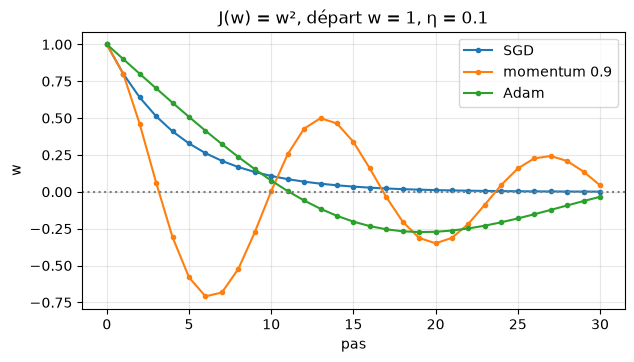

In [6]:
# A la main
w_sgd = 1.0
for t in range(2):
    w_sgd = w_sgd - 0.1 * (2 * w_sgd)
    print(f"SGD      pas {t + 1} : w = {w_sgd:.4f}")

w_mom, v = 1.0, 0.0
for t in range(2):
    g = 2 * w_mom
    v = 0.9 * v + g
    w_mom = w_mom - 0.1 * v
    print(f"momentum pas {t + 1} : g = {g:.2f}, v = {v:.2f}, w = {w_mom:.4f}")

g = 2.0                                        # gradient au départ (w = 1)
m, s = 0.1 * g, 0.001 * g ** 2
m_hat, s_hat = m / (1 - 0.9), s / (1 - 0.999)
print(f"Adam     pas 1 : m_hat = {m_hat:.4f} (= g), s_hat = {s_hat:.4f} (= g^2), w = {1 - 0.1 * m_hat / math.sqrt(s_hat):.4f}")


# Avec les optimiseurs de PyTorch : mêmes nombres, puis 30 pas pour voir la suite
def trajectoire(make_opt, n_pas=30):
    w = torch.tensor([1.0], requires_grad=True)
    opt = make_opt([w])
    valeurs = [1.0]
    for _ in range(n_pas):
        opt.zero_grad()
        (w ** 2).sum().backward()          # J = w^2, donc w.grad = 2w
        opt.step()
        valeurs.append(w.item())
    return valeurs


trajs = {
    "SGD": trajectoire(lambda p: torch.optim.SGD(p, lr=0.1)),
    "momentum 0.9": trajectoire(lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9)),
    "Adam": trajectoire(lambda p: torch.optim.Adam(p, lr=0.1)),
}
print("\nPyTorch, w après 1 et 2 pas :", {k: [round(x, 4) for x in t[1:3]] for k, t in trajs.items()})

plt.figure(figsize=(7, 3.6))
for name, t in trajs.items():
    plt.plot(t, "o-", ms=3, label=name)
plt.axhline(0, color="gray", ls=":")
plt.xlabel("pas"); plt.ylabel("w"); plt.legend(); plt.grid(alpha=0.3)
plt.title("J(w) = w², départ w = 1, η = 0.1")
plt.show()

💡 Sur 30 pas : le SGD descend régulièrement ($0.8^t$) ; le momentum descend plus vite, **dépasse** 0 puis oscille en s'amortissant (la bille qui a de l'élan) ; Adam fait des pas d'environ $\eta = 0.1$ et descend presque en ligne droite au début, puis oscille près de 0.

La slide 20 montre la même chose sur une vallée étroite $J = w_1^2/100 + w_2^2$ (très plate selon $w_1$, très raide selon $w_2$), en partant de $(-9, 2)$ pour 40 pas. On la reproduit :

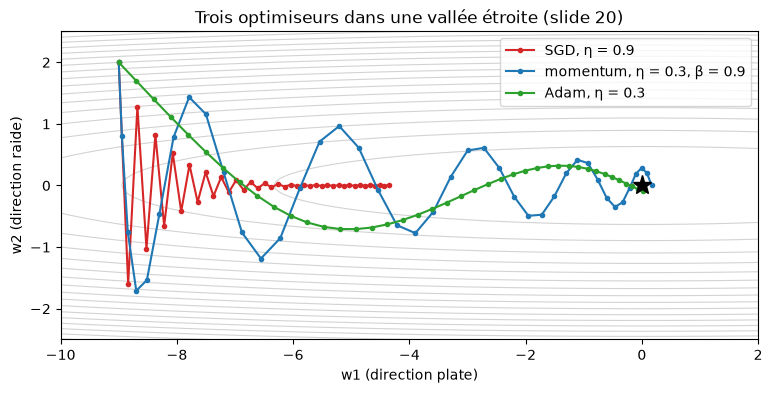

SGD, η = 0.9                 point d'arrivée : (-4.35, 0.00)
momentum, η = 0.3, β = 0.9   point d'arrivée : (0.17, 0.00)
Adam, η = 0.3                point d'arrivée : (0.02, -0.10)


In [7]:
def trajectoire_2d(make_opt, n_pas=40):
    w = torch.tensor([-9.0, 2.0], requires_grad=True)
    opt = make_opt([w])
    points = [w.detach().clone()]
    for _ in range(n_pas):
        opt.zero_grad()
        (w[0] ** 2 / 100 + w[1] ** 2).backward()
        opt.step()
        points.append(w.detach().clone())
    return torch.stack(points)


chemins = {
    "SGD, η = 0.9": trajectoire_2d(lambda p: torch.optim.SGD(p, lr=0.9)),
    "momentum, η = 0.3, β = 0.9": trajectoire_2d(lambda p: torch.optim.SGD(p, lr=0.3, momentum=0.9)),
    "Adam, η = 0.3": trajectoire_2d(lambda p: torch.optim.Adam(p, lr=0.3)),
}
W1, W2 = np.meshgrid(np.linspace(-10, 2, 200), np.linspace(-2.5, 2.5, 200))
plt.figure(figsize=(9, 4))
plt.contour(W1, W2, W1 ** 2 / 100 + W2 ** 2, levels=20, colors="lightgray", linewidths=0.8)
for (name, pts), color in zip(chemins.items(), ["C3", "C0", "C2"]):
    plt.plot(pts[:, 0], pts[:, 1], "o-", ms=3, color=color, label=name)
plt.plot(0, 0, "k*", ms=14)
plt.xlabel("w1 (direction plate)"); plt.ylabel("w2 (direction raide)"); plt.legend()
plt.title("Trois optimiseurs dans une vallée étroite (slide 20)")
plt.show()
for name, pts in chemins.items():
    print(f"{name:28s} point d'arrivée : ({pts[-1, 0]:.2f}, {pts[-1, 1]:.2f})")

💡 Le SGD ($\eta = 0.9$) zigzague violemment selon $w_2$ (la direction raide) puis **rampe** selon $w_1$ : après 40 pas il n'est qu'en $w_1 = -4.35$, car selon $w_1$ chaque pas ne fait que $w_1 \leftarrow (1 - 0.9/50)\,w_1 = 0.982\,w_1$, et $9 \times 0.982^{40} \approx 4.35$. Impossible d'augmenter $\eta$ : la direction raide divergerait. Le momentum prend de l'élan selon $w_1$ et atteint le minimum ; Adam donne à $w_1$ et à $w_2$ des pas de même taille malgré des gradients 50 fois différents, et arrive aussi au minimum.

> ✅ **À retenir (exercice du cours 4)**
>
> - Momentum : $v \leftarrow \beta v + g$, $w \leftarrow w - \eta v$. Il accélère dans les directions constantes et amortit les zigzags, mais peut dépasser le minimum.
> - Adam : momentum + division par $\sqrt{\hat s}$ (un pas par paramètre) + correction du biais. Le premier pas vaut exactement $\eta$, quel que soit le gradient.

---
## Exercice du cours 5 : quatre entraînements à diagnostiquer (slide 25)

> **Énoncé** : pour chaque entraînement (A, B, C, D) : que se passe-t-il, et quelle est la première chose que tu changes ? Pourquoi la courbe plate de l'entraînement C est-elle **exactement** à 2.30 ?
>
> - **Run A** : la loss d'entraînement descend vers 0 ; la loss de validation descend jusqu'à environ 0.7 vers l'époque 18, puis remonte vers 1.0.
> - **Run B** : la loss monte en flèche (échelle logarithmique, plus de 100 à l'époque 7), puis devient `nan` à partir de l'époque 8.
> - **Run C** : entraînement et validation restent plats à 2.30 du début à la fin.
> - **Run D** : les deux loss descendent un peu puis plafonnent ensemble, haut (environ 1.25), très proches l'une de l'autre.

### 📖 Le cours : le tableau du diagnostic (slide 23)

| Symptôme | Cause probable | Remède |
|---|---|---|
| la loss devient énorme, puis `nan` | pas $\eta$ trop grand, gradients qui explosent | diviser $\eta$ par 10 ; gradient clipping ; vérifier que les entrées sont normalisées |
| loss plate dès le départ (à $\ln C$) | $\eta$ trop petit ; un bug (pas de `step()`, pas de `zero_grad()`, étiquettes mélangées) ; ReLU mortes ; réseau sigmoïde profond | faire d'abord surapprendre **un petit batch** ; vérifier la boucle ; ReLU + init de He, batch norm |
| la loss d'entraînement baisse, celle de validation monte | surapprentissage | plus de données, weight decay, dropout, early stopping |
| les deux loss restent hautes et proches | sous-apprentissage | modèle plus gros, entraîner plus longtemps, $\eta$ plus grand, moins de régularisation |
| loss très bruitée, ne se stabilise pas | $\eta$ trop grand pour la fin de l'entraînement, batch trop petit | un schedule (décroissance de $\eta$), un batch plus grand |

**Le gradient clipping** (slide 24) : si la norme du gradient **complet** (tous les paramètres ensemble) dépasse un seuil $c$, on le raccourcit en gardant sa direction : $g \leftarrow c\,g/\lVert g \rVert$. Exemple : $g = (3, 4)$, $\lVert g \rVert = 5$, $c = 1$ donne $g = (0.6, 0.8)$. On l'applique entre `backward()` et `step()` avec `clip_grad_norm_` ; c'est le standard pour les RNN (session 8) et un filet de sécurité ailleurs.

### ✍️ Le diagnostic, run par run

**Run A : surapprentissage.** La loss d'entraînement va vers 0 pendant que celle de validation, après un minimum, **remonte** : le réseau apprend par cœur. C'est exactement la situation de la slide 4.
➡️ **Première chose à changer** : l'**early stopping** (garder le checkpoint de la meilleure époque de validation, vers l'époque 18 ; c'est gratuit). Ensuite, régulariser : weight decay, dropout, et si possible plus de données.

**Run B : divergence.** La loss **explose** (échelle log : elle est multipliée à chaque époque) puis devient `nan` (« not a number », le résultat d'un calcul qui a débordé, comme $\infty - \infty$). Les pas sont trop grands : chaque mise à jour envoie les poids plus loin du minimum au lieu de s'en rapprocher, les gradients grossissent, et ainsi de suite.
➡️ **Première chose à changer** : **diviser $\eta$ par 10**. Ensuite : gradient clipping, et vérifier que les entrées sont bien normalisées.

**Run C : rien n'est appris.** Les deux loss sont plates à 2.30 dès la première époque : le réseau ne bouge pas, ou bouge sans rien apprendre.
➡️ **Première chose à changer** : **vérifier la boucle d'entraînement** (y a-t-il bien `optimizer.step()` ? `optimizer.zero_grad()` ? les étiquettes correspondent-elles aux images ?) en essayant de faire surapprendre **un seul petit batch** : un réseau correct doit y arriver en quelques dizaines de pas. Si la boucle est bonne : $\eta$ trop petit, ReLU mortes, ou réseau sigmoïde trop profond (session 5) : ReLU + init de He, batch norm.

**Run D : sous-apprentissage.** Les deux loss restent **hautes** (environ 1.25, alors qu'un bon modèle descend vers 0.4) et **collées** l'une à l'autre : le modèle n'arrive même pas à bien faire sur ses données d'entraînement, il n'y a donc rien à surapprendre.
➡️ **Première chose à changer** : un **modèle plus gros** (plus de neurones ou de couches). Ou entraîner plus longtemps, un $\eta$ plus grand, et retirer de la régularisation s'il y en a trop.

### ✍️ Pourquoi exactement 2.30 ?

FashionMNIST a $C = 10$ classes. Un réseau qui ne sait rien répond la même probabilité $1/C$ pour chaque classe : ses logits sont (presque) égaux, et la softmax de nombres égaux donne $1/10$ partout. L'entropie croisée d'une image vaut alors, quelle que soit sa vraie classe :

$$\mathcal{L} = -\ln p_y = -\ln\frac{1}{10} = \ln 10 \approx 2.30$$

C'est la loss d'un réseau fraîchement initialisé (ses logits sont tous proches de 0), et aussi la meilleure loss possible pour un modèle qui **ignore l'image** : avec des classes équilibrées, la meilleure réponse constante est justement $1/10$ partout. Une courbe plate **exactement** à $\ln C$ signifie donc : **le réseau n'a rien appris de l'image**.

### 💻 Les quatre runs, reproduits pour de vrai

On recrée les quatre situations sur nos 2 000 images, avec les outils du TP :

- **A** : le grand réseau de la slide 4, SGD avec momentum, $\eta = 0.05$ (réglage raisonnable), 30 époques ;
- **B** : le même avec $\eta = 1.0$ (beaucoup trop grand). Il diverge si vite qu'on suit sa loss **à chaque pas** (chaque batch) de la première époque, au lieu d'une valeur par époque ;
- **C** : le même, mais avec une boucle qui **oublie** `optimizer.step()` ;
- **D** : un réseau minuscule 784-1-10 (**un seul** neurone caché).

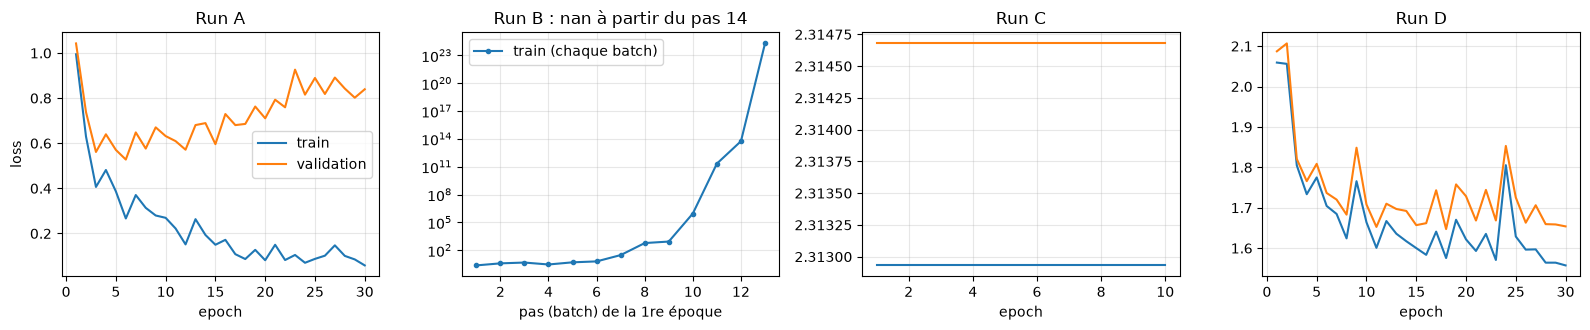

Run A : train loss 0.994 -> 0.058 | val loss min 0.528, finale 0.839 | précision train 0.979, val 0.815
Run C : train loss 2.313 -> 2.313 | val loss min 2.315, finale 2.315 | précision train 0.088, val 0.079
Run D : train loss 2.059 -> 1.557 | val loss min 1.647, finale 1.654 | précision train 0.289, val 0.274
Run B : loss des premiers pas : ['2.29', '3.81', '4.65', '2.88', '4.92', '6.19', '29.7', '588', '854', '9.03e+05', '2.17e+11', '5.66e+13', '1.98e+24', 'nan']


In [8]:
def grand_reseau():
    # le réseau 784-512-512-10 de la slide 4 (le TP le reconstruit à l'exercice 1)
    return nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10))


def epoque_sans_step(model, loader, loss_fn, optimizer):
    # le bug du run C : tout est là... sauf optimizer.step(), donc les poids ne bougent jamais
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss_fn(model(xb), yb).backward()


runs = {}
torch.manual_seed(0); mA = grand_reseau()
runs["A"] = fit(mA, torch.optim.SGD(mA.parameters(), lr=0.05, momentum=0.9), EPOCHS)
torch.manual_seed(0); mC = grand_reseau()
runs["C"] = fit(mC, torch.optim.SGD(mC.parameters(), lr=0.05, momentum=0.9), EPOCHS_SHORT, train_epoch_fn=epoque_sans_step)
torch.manual_seed(0); mD = nn.Sequential(nn.Linear(784, 1), nn.ReLU(), nn.Linear(1, 10))
runs["D"] = fit(mD, torch.optim.SGD(mD.parameters(), lr=0.05, momentum=0.9), EPOCHS)

# Run B : la boucle d'une époque écrite à la main, pour noter la loss de CHAQUE batch
torch.manual_seed(0); mB = grand_reseau()
optB = torch.optim.SGD(mB.parameters(), lr=1.0, momentum=0.9)
torch.manual_seed(1)
pertes_B = []
mB.train()
for xb, yb in train_loader:
    optB.zero_grad()
    loss = loss_fn(mB(xb), yb)
    pertes_B.append(loss.item())
    loss.backward()
    optB.step()
premier_nan = next((i + 1 for i, v in enumerate(pertes_B) if math.isnan(v)), None)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, name in zip([axes[0], axes[2], axes[3]], ["A", "C", "D"]):
    h = runs[name]
    e = range(1, len(h["train_loss"]) + 1)
    ax.plot(e, h["train_loss"], label="train")
    ax.plot(e, h["val_loss"], label="validation")
    ax.set_title(f"Run {name}"); ax.set_xlabel("epoch")
axes[1].plot(range(1, len(pertes_B) + 1), pertes_B, "o-", ms=3, label="train (chaque batch)")
axes[1].set_yscale("log"); axes[1].set_xlabel("pas (batch) de la 1re époque")
axes[1].set_title(f"Run B : nan à partir du pas {premier_nan}")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].set_ylabel("loss"); axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

for name, h in runs.items():
    print(f"Run {name} : train loss {h['train_loss'][0]:.3f} -> {h['train_loss'][-1]:.3f} | "
          f"val loss min {min(h['val_loss']):.3f}, finale {h['val_loss'][-1]:.3f} | "
          f"précision train {h['train_acc'][-1]:.3f}, val {h['val_acc'][-1]:.3f}")
print("Run B : loss des premiers pas :", [f"{v:.3g}" for v in pertes_B[:premier_nan]])

In [9]:
# Pourquoi 2.30 : un réseau neuf donne (presque) 1/10 à chaque classe
torch.manual_seed(0)
neuf = grand_reseau()
neuf.eval()
with torch.no_grad():
    logits = neuf(X_val)
    probas = torch.softmax(logits, dim=1)
print(f"loss d'un réseau neuf : {loss_fn(logits, y_val).item():.3f}   (ln 10 = {math.log(10):.3f})")
print(f"logits entre {logits.min().item():.2f} et {logits.max().item():.2f} ; "
      f"probabilités entre {probas.min().item():.3f} et {probas.max().item():.3f} (1/10 = 0.1)")

loss d'un réseau neuf : 2.315   (ln 10 = 2.303)
logits entre -0.39 et 0.54 ; probabilités entre 0.063 et 0.159 (1/10 = 0.1)


💡 **Ce qu'on observe.** Les quatre runs reproduisent la slide 25 :

- **A** : la loss d'entraînement tombe de 0.99 à 0.06 pendant que celle de validation, minimale à 0.53, remonte à 0.84. Précision : 97.9 % en entraînement, 81.5 % en validation. **Surapprentissage.**
- **B** : avec $\eta = 1.0$, la loss passe de 2.3 à plus de $10^{24}$ en 13 pas, puis devient `nan` au pas 14, **dès la première époque**. **Divergence.**
- **C** : sans `optimizer.step()`, les poids ne bougent jamais : la loss reste exactement à sa valeur de départ (2.31) et la précision au niveau du hasard. **Rien n'est appris.**
- **D** : avec un seul neurone caché, les deux loss restent hautes et proches (1.56 en entraînement, 1.65 en validation, 27 % de précision). **Sous-apprentissage** : toute l'image doit passer par un seul nombre, c'est beaucoup trop peu.

La deuxième cellule confirme le 2.30 : un réseau neuf a des logits entre -0.39 et 0.54, donc des probabilités entre 0.06 et 0.16, toutes proches de 1/10 ; sa loss vaut 2.315, à peine au-dessus de $\ln 10 = 2.303$ (ses probabilités ne sont pas tout à fait égales).

> ✅ **À retenir (exercice du cours 5)**
>
> - **Toujours tracer les deux courbes** (entraînement et validation) : le diagnostic se lit dessus.
> - `nan` ou explosion : $\eta$ trop grand. Plat à $\ln C$ : rien n'est appris (vérifier la boucle d'abord). Validation qui remonte : surapprentissage. Les deux hautes et collées : sous-apprentissage.
> - $\ln 10 \approx 2.30$ est la loss d'un modèle qui répond $1/10$ partout.

---
# Partie 2 : le TP06, mieux entraîner un réseau sur FashionMNIST

On reprend le TP dans l'ordre. Les données et les fonctions utilitaires sont déjà chargées (section 0).

---
## TP partie A : provoquer le surapprentissage

### TP · Exercice 1 : un grand réseau

> **Énoncé** : écrire `make_big_model()` qui renvoie le réseau du cours : `784 -> 512 -> 512 -> 10`, avec une ReLU après chaque couche cachée. Pas de softmax à la fin : `nn.CrossEntropyLoss` prend les scores bruts (logits).

📖 **Rappels**

- `nn.Linear(n_in, n_out)` : une couche dense, avec des poids de forme `(n_out, n_in)` et un biais de taille `n_out`.
- `nn.ReLU()` applique $\max(0, z)$ élément par élément (session 5).
- `nn.Sequential(couche1, couche2, ...)` enchaîne les couches : la sortie de l'une est l'entrée de la suivante.
- Pas de `nn.Flatten()` : les images sont **déjà** aplaties en vecteurs de 784 dans la section 0 (`.reshape(-1, 784)`).

✍️ **Le nombre de paramètres** :

$$\underbrace{784 \times 512 + 512}_{401\,920} + \underbrace{512 \times 512 + 512}_{262\,656} + \underbrace{512 \times 10 + 10}_{5\,130} = 669\,706$$

Près de **335 paramètres par image d'entraînement** (669 706 pour 2 000 images) : de quoi apprendre chaque image par cœur.

🧩 **Le code ligne par ligne** : 5 modules dans le `nn.Sequential`, dans l'ordre Linear, ReLU, Linear, ReLU, Linear. Chaque `nn.Linear` reçoit la taille de sortie de la précédente (784, puis 512, puis 512).

In [10]:
def make_big_model():
    ### START CODE HERE ###
    model = nn.Sequential(
        nn.Linear(784, 512),    # couche cachée 1 : 784 pixels -> 512 neurones
        nn.ReLU(),
        nn.Linear(512, 512),    # couche cachée 2 : 512 -> 512
        nn.ReLU(),
        nn.Linear(512, 10),     # sortie : 10 logits, sans activation
    )
    ### END CODE HERE ###
    return model


torch.manual_seed(0)
_m = make_big_model()
assert isinstance(_m, nn.Sequential), "return an nn.Sequential"
assert _m(torch.zeros(3, 784)).shape == (3, 10), "the output must have shape (batch, 10)"
assert count_parameters(_m) == 669_706, f"expected 669 706 parameters, found {count_parameters(_m)}"
print("Exercise validated! The network has", count_parameters(_m), "parameters for 2 000 images.")

Exercise validated! The network has 669706 parameters for 2 000 images.


### TP · Exercice 2 : l'entraîner

> **Énoncé** : créer le modèle avec `make_big_model()` (le nommer `model_base`) et un optimiseur **SGD avec momentum** : `torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)`. Puis entraîner avec `history_base = fit(model_base, optimizer, EPOCHS)`.

🧩 **Le code ligne par ligne** (3 lignes)

1. `model_base = make_big_model()` : un réseau neuf. La graine `torch.manual_seed(0)` juste avant garantit que tout le monde part des mêmes poids initiaux.
2. `optimizer = torch.optim.SGD(model_base.parameters(), lr=0.05, momentum=0.9)` : `model_base.parameters()` donne à l'optimiseur **tous** les tenseurs qu'il doit mettre à jour (poids et biais des 3 couches) ; `lr` est $\eta$ ; `momentum` est le $\beta$ du cours (exercice du cours 4).
3. `history_base = fit(model_base, optimizer, EPOCHS)` : 30 époques ; `fit` renvoie l'historique (5 listes de 30 valeurs).

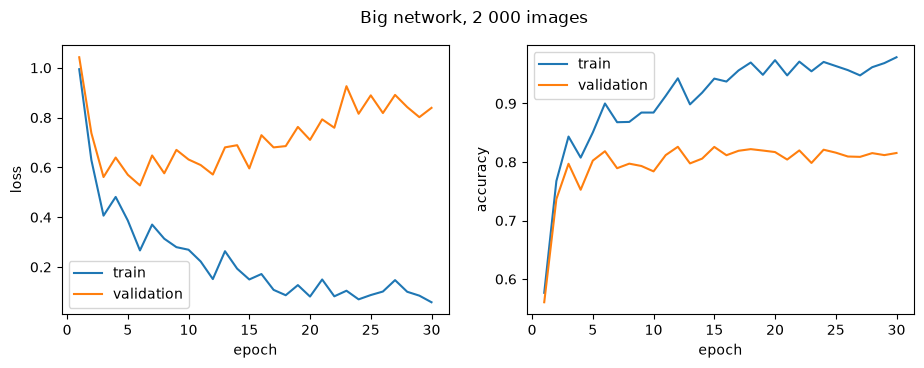

Exercise validated!


In [11]:
torch.manual_seed(0)
### START CODE HERE ###
model_base = make_big_model()                                                # un réseau neuf
optimizer = torch.optim.SGD(model_base.parameters(), lr=0.05, momentum=0.9)   # SGD + momentum
history_base = fit(model_base, optimizer, EPOCHS)                            # 30 époques
### END CODE HERE ###

assert history_base is not None and len(history_base["val_loss"]) == EPOCHS, "call fit(model_base, optimizer, EPOCHS)"
assert history_base["train_loss"][-1] < history_base["train_loss"][0], "the training loss should decrease"
plot_history(history_base, "Big network, 2 000 images")
print("Exercise validated!")

### TP · Exercice 3 : mesurer le surapprentissage

> **Énoncé** : à partir de `history_base`, calculer `gap_base` (précision d'entraînement finale moins précision de validation finale) et `best_epoch_base` (l'époque, comptée à partir de 1, où la loss de validation est la plus petite).

🧩 **Le code ligne par ligne**

- `history_base["train_acc"][-1]` : le **dernier** élément de la liste, c'est-à-dire la précision d'entraînement à la dernière époque (`L[-1]` en Python). Idem pour `"val_acc"`. L'écart est leur différence.
- `np.argmin(liste)` renvoie l'**indice** du plus petit élément, compté à partir de **0**. Les époques sont comptées à partir de **1** : on ajoute 1. `int(...)` convertit l'entier NumPy en entier Python.

In [12]:
### START CODE HERE ###
gap_base = history_base["train_acc"][-1] - history_base["val_acc"][-1]     # écart final train - validation
best_epoch_base = int(np.argmin(history_base["val_loss"])) + 1            # indice compté de 0, donc + 1
### END CODE HERE ###

assert gap_base is not None and abs(gap_base - (history_base["train_acc"][-1] - history_base["val_acc"][-1])) < 1e-9
assert best_epoch_base == int(np.argmin(history_base["val_loss"])) + 1, "epochs are counted from 1"
assert gap_base > 0.08, f"the gap should be large (overfitting), found {gap_base:.3f}"
assert history_base["val_loss"][-1] > min(history_base["val_loss"]), "the validation loss should rise at the end"
print(f"Exercise validated! Gap {gap_base:.3f}, best validation loss at epoch {best_epoch_base} of {EPOCHS}.")

Exercise validated! Gap 0.164, best validation loss at epoch 6 of 30.


💡 **Ce qu'on observe.** Écart de **0.164** (97.9 % de précision en entraînement contre 81.5 % en validation). La meilleure loss de validation est atteinte à l'**époque 6** sur 30 (0.528), puis elle remonte jusqu'à 0.839 pendant que la loss d'entraînement descend à 0.06.

La précision d'entraînement continue de monter alors que celle de validation plafonne : l'écart est grand. La loss de validation atteint son minimum après quelques époques, puis remonte : le réseau devient **trop sûr de lui** sur des images qu'il n'a jamais vues. Pourquoi la loss remonte alors que la précision de validation ne baisse presque pas ? La précision ne regarde que la classe prédite ; la loss regarde la **confiance**. Une erreur commise avec 99 % de confiance coûte $-\ln(0.01) \approx 4.6$, contre $-\ln(0.5) \approx 0.7$ avec 50 % : un réseau trop confiant voit sa loss grimper même si ses réponses changent peu. Tout l'entraînement après la meilleure époque est du temps perdu, voire nuisible.

---
## TP partie B : la régularisation

### TP · Exercice 4 : la pénalité L2

> **Énoncé** : écrire `l2_penalty(model, lam)` qui renvoie $\frac{\lambda}{2}\sum W^2$ : la somme des carrés de **tous les poids** des couches `nn.Linear` (pas les biais), fois `lam / 2`.

📖 C'est le terme ajouté au coût dans l'exercice du cours 1. Les biais ne sont pas pénalisés : un biais décale seulement la sortie d'un neurone, il ne rend pas la fonction plus « tordue ».

🧩 **Le code ligne par ligne**

- `total = 0.0` : on part de 0 et on accumule.
- `for layer in model.modules()` : parcourt **toutes** les couches du modèle (y compris celles cachées dans des sous-modules). `isinstance(layer, nn.Linear)` garde les couches linéaires (les ReLU n'ont pas de poids).
- `(layer.weight ** 2).sum()` : la somme des carrés de toutes les cases de la matrice des poids. On n'utilise **pas** `layer.bias`.
- `penalty = lam / 2 * total` : le facteur $\lambda/2$.

Le résultat est un **tenseur** relié au graphe de calcul : on pourrait l'ajouter à la loss (`loss = loss_fn(...) + l2_penalty(model, lam)`) et `backward()` calculerait tout seul son gradient $\lambda W$. C'est exactement ce que fait `weight_decay` dans l'optimiseur (on le vérifie juste après).

✍️ Le test : poids $(2, -1, 0, 1)$ et $(1, 3)$, biais ignorés, $\lambda = 0.5$ : $0.25 \times (4 + 1 + 0 + 1 + 1 + 9) = 0.25 \times 16 = 4.0$.

ℹ️ PyTorch affiche un avertissement (`UserWarning: Converting a tensor with requires_grad=True to a scalar...`) en exécutant l'assert : il convertit en `float` notre pénalité, qui est restée reliée au graphe de calcul (c'est voulu, pour pouvoir la dériver). C'est sans danger ici : l'avertissement rappelle juste que ce `float` ne transmettra pas de gradient.

In [13]:
def l2_penalty(model, lam):
    ### START CODE HERE ###
    total = 0.0
    for layer in model.modules():                   # toutes les couches du modèle
        if isinstance(layer, nn.Linear):            # seulement celles qui ont des poids
            total = total + (layer.weight ** 2).sum()   # somme des carrés des poids (PAS des biais)
    penalty = lam / 2 * total
    ### END CODE HERE ###
    return penalty


_tiny = nn.Sequential(nn.Linear(2, 2), nn.ReLU(), nn.Linear(2, 1))
with torch.no_grad():
    _tiny[0].weight.copy_(torch.tensor([[2.0, -1.0], [0.0, 1.0]])); _tiny[0].bias.fill_(5.0)
    _tiny[2].weight.copy_(torch.tensor([[1.0, 3.0]])); _tiny[2].bias.fill_(7.0)
_p = l2_penalty(_tiny, 0.5)
assert _p is not None, "return the penalty"
assert abs(float(_p) - 0.25 * (4 + 1 + 0 + 1 + 1 + 9)) < 1e-6, f"expected 4.0, found {float(_p)} (biases must not be counted)"
print("Exercise validated!")

Exercise validated!


<ipython-input>:18: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  assert abs(float(_p) - 0.25 * (4 + 1 + 0 + 1 + 1 + 9)) < 1e-6, f"expected 4.0, found {float(_p)} (biases must not be counted)"


In [14]:
# Bonus : autograd retrouve bien le gradient lambda * W du cours
_tiny.zero_grad()
l2_penalty(_tiny, 0.5).backward()
print("gradient de la pénalité pour la couche 0 :\n", _tiny[0].weight.grad)
print("lambda * W :\n", 0.5 * _tiny[0].weight.detach())
print("gradient des biais (non pénalisés) :", _tiny[0].bias.grad)

gradient de la pénalité pour la couche 0 :
 tensor([[ 1.0000, -0.5000],
        [ 0.0000,  0.5000]])
lambda * W :
 tensor([[ 1.0000, -0.5000],
        [ 0.0000,  0.5000]])
gradient des biais (non pénalisés) : None


### TP · Exercice 5 : une mise à jour avec weight decay, à la main

> **Énoncé** : la mise à jour est $w \leftarrow w - \eta\left(\frac{\partial J}{\partial w} + \lambda w\right)$. Calculer `w_new` avec les nombres de l'exercice du cours 1 : $w = (2, -1)$, $\partial J/\partial w = (0.5, -0.5)$, $\eta = 0.1$, $\lambda = 0.5$. L'assert compare avec `torch.optim.SGD(..., weight_decay=0.5)`.

🧩 Une seule ligne, la formule recopiée : `grad + lam * w` est le gradient total (données + pénalité), multiplié par `lr` et retiré de `w`. Les opérations sur des tenseurs se font **élément par élément**, donc les deux poids sont traités d'un coup. On attend $(1.85, -0.90)$, comme à la main.

In [15]:
w = torch.tensor([2.0, -1.0])
grad = torch.tensor([0.5, -0.5])
lr, lam = 0.1, 0.5
### START CODE HERE ###
w_new = w - lr * (grad + lam * w)      # = (1 - lr*lam) * w - lr * grad = 0.95 w - 0.1 grad
### END CODE HERE ###

_w = w.clone().requires_grad_(True)
_opt = torch.optim.SGD([_w], lr=lr, weight_decay=lam)
_w.grad = grad.clone()
_opt.step()
assert w_new is not None and torch.allclose(w_new, torch.tensor([1.85, -0.90])), f"expected (1.85, -0.90), found {w_new}"
assert torch.allclose(w_new, _w.detach()), "PyTorch's weight_decay should give the same result"
print("Exercise validated! Same result as the course and as torch.optim.SGD(weight_decay=0.5).")

Exercise validated! Same result as the course and as torch.optim.SGD(weight_decay=0.5).


### TP · Exercice 6 : entraîner avec weight decay

> **Énoncé** : même modèle, même optimiseur qu'à l'exercice 2, plus `weight_decay=1e-2`. Stocker l'historique dans `history_wd` et l'écart final dans `gap_wd`. Nommer le modèle `model_wd`.

🧩 **Le code ligne par ligne** : exactement l'exercice 2, avec un argument en plus.

- `torch.optim.SGD(..., weight_decay=1e-2)` : à chaque pas, PyTorch ajoute $\lambda w = 0.01\,w$ au gradient de chaque paramètre (exercice 5). Remarque : PyTorch l'applique aussi aux biais ; ce n'est pas gênant ici.
- La variable doit s'appeler `optimizer` : l'assert vérifie son `weight_decay`.
- `gap_wd` : même calcul que `gap_base`.

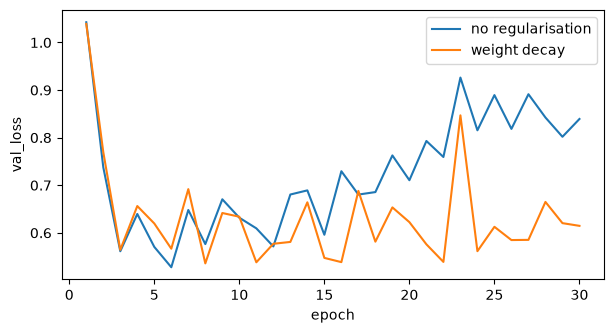

Exercise validated! Gap 0.164 without, 0.096 with weight decay.


In [16]:
torch.manual_seed(0)
### START CODE HERE ###
model_wd = make_big_model()
optimizer = torch.optim.SGD(model_wd.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-2)   # + lambda w
history_wd = fit(model_wd, optimizer, EPOCHS)
gap_wd = history_wd["train_acc"][-1] - history_wd["val_acc"][-1]
### END CODE HERE ###

assert history_wd is not None and len(history_wd["val_loss"]) == EPOCHS
assert abs(gap_wd - (history_wd["train_acc"][-1] - history_wd["val_acc"][-1])) < 1e-9
assert optimizer.param_groups[0]["weight_decay"] == 1e-2, "use weight_decay=1e-2"
assert gap_wd < gap_base, f"weight decay should reduce the gap ({gap_wd:.3f} versus {gap_base:.3f})"
plot_compare({"no regularisation": history_base, "weight decay": history_wd}, "val_loss")
print(f"Exercise validated! Gap {gap_base:.3f} without, {gap_wd:.3f} with weight decay.")

In [17]:
# Bonus : le weight decay a bien gardé les poids plus petits
def norme_poids(model):
    return math.sqrt(sum((m.weight ** 2).sum().item() for m in model.modules() if isinstance(m, nn.Linear)))

print(f"norme de tous les poids : {norme_poids(model_base):.1f} sans régularisation, {norme_poids(model_wd):.1f} avec weight decay")

norme de tous les poids : 25.8 sans régularisation, 7.5 avec weight decay


💡 **Ce qu'on observe.** Avec weight decay, l'écart tombe de 0.164 à **0.096**, et la norme de tous les poids de 25.8 à 7.5 : l'élastique a bien tiré les poids vers 0. Sur le graphique, la loss de validation ne s'envole plus comme celle de la baseline (0.615 en fin d'entraînement au lieu de 0.839) : le réseau, aux poids plus petits, reste moins sûr de lui.

### TP · Exercice 7 : le dropout inversé à la main

> **Énoncé** : écrire `dropout_forward(a, p, mask)` : `mask` contient des 1 (garder) et des 0 (éteindre) ; renvoyer $\tilde a = \dfrac{\text{mask} \odot a}{1 - p}$.

🧩 Une ligne : `mask * a` est le produit **élément par élément** ($\odot$) : les valeurs éteintes deviennent 0, les autres restent. Puis `/ (1 - p)` remet à l'échelle les survivants.

Les deux tests : l'exercice du cours 2 ($a = (2, 1, 4, 3)$, masque $(1, 0, 1, 0)$, on attend $(4, 0, 8, 0)$), puis **un million** de valeurs avec un masque aléatoire ($p = 0.3$). Par la loi des grands nombres, la moyenne de $\tilde a$ doit être très proche de celle de $a$ : c'est la preuve expérimentale de $\mathbb{E}[\tilde a_i] = a_i$. `torch.bernoulli(torch.full(shape, 1 - p))` tire chaque case du masque à 1 avec probabilité $1 - p$.

In [18]:
def dropout_forward(a, p, mask):
    ### START CODE HERE ###
    out = mask * a / (1 - p)       # éteindre (x 0) ou garder (x 1), puis remettre à l'échelle
    ### END CODE HERE ###
    return out


_out = dropout_forward(torch.tensor([2.0, 1.0, 4.0, 3.0]), 0.5, torch.tensor([1.0, 0.0, 1.0, 0.0]))
assert _out is not None and torch.allclose(_out, torch.tensor([4.0, 0.0, 8.0, 0.0])), f"expected (4, 0, 8, 0), found {_out}"
torch.manual_seed(0)
_a = torch.rand(1_000_000) * 3
_mask = torch.bernoulli(torch.full(_a.shape, 0.7))           # keep with probability 0.7, so p = 0.3
assert abs(dropout_forward(_a, 0.3, _mask).mean() - _a.mean()) < 0.01, "the mean must be preserved (divide by 1 - p)"
print("Exercise validated!")

Exercise validated!


### TP · Exercice 8 : un modèle avec dropout

> **Énoncé** : écrire `make_dropout_model(p)` : le grand réseau avec un `nn.Dropout(p)` **après chaque ReLU cachée** (Linear, ReLU, Dropout, Linear, ReLU, Dropout, Linear).

🧩 **Le code ligne par ligne**

- On reprend `make_big_model` et on insère `nn.Dropout(p)` après chaque `nn.ReLU()` : il éteint des **sorties de neurones cachés**.
- **Pas de dropout après la dernière couche** : on ne veut pas effacer des logits, c'est la réponse du réseau.
- `nn.Dropout` n'a **aucun paramètre** (le nombre reste 669 706) : c'est une opération, pas une couche apprise.

Les asserts vérifient les deux modes : en `train()`, deux passages sur la même entrée donnent des sorties **différentes** (deux masques tirés au hasard) ; en `eval()`, elles sont **identiques**.

In [19]:
def make_dropout_model(p):
    ### START CODE HERE ###
    model = nn.Sequential(
        nn.Linear(784, 512), nn.ReLU(), nn.Dropout(p),    # on éteint des sorties de la couche cachée 1
        nn.Linear(512, 512), nn.ReLU(), nn.Dropout(p),    # ... et de la couche cachée 2
        nn.Linear(512, 10),                               # pas de dropout sur les logits
    )
    ### END CODE HERE ###
    return model


_m = make_dropout_model(0.5)
assert _m is not None and sum(isinstance(l, nn.Dropout) for l in _m) == 2, "two nn.Dropout layers"
assert count_parameters(_m) == 669_706, "dropout adds no parameter"
_x = X_train[:5]
_m.train()
assert not torch.allclose(_m(_x), _m(_x)), "in train mode two passes should differ"
_m.eval()
assert torch.allclose(_m(_x), _m(_x)), "in eval mode two passes should be identical"
print("Exercise validated!")

Exercise validated!


### TP · Exercice 9 : entraîner avec dropout

> **Énoncé** : entraîner `model_drop = make_dropout_model(0.5)` avec l'optimiseur de l'exercice 2 (sans weight decay). Stocker `history_drop` et `gap_drop`.

🧩 Même recette qu'à l'exercice 2. Rien à faire pour les modes : `train_one_epoch` appelle `model.train()` (dropout actif) et `evaluate` appelle `model.eval()` (dropout éteint). La précision d'entraînement est donc mesurée **sans** dropout, comme celle de validation : la comparaison est juste.

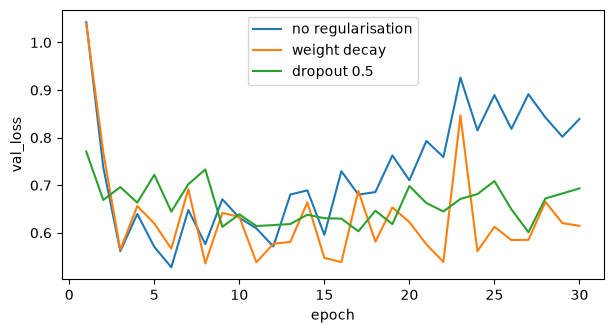

Exercise validated! Gap 0.164 without, 0.068 with dropout.


In [20]:
torch.manual_seed(0)
### START CODE HERE ###
model_drop = make_dropout_model(0.5)
optimizer = torch.optim.SGD(model_drop.parameters(), lr=0.05, momentum=0.9)
history_drop = fit(model_drop, optimizer, EPOCHS)
gap_drop = history_drop["train_acc"][-1] - history_drop["val_acc"][-1]
### END CODE HERE ###

assert history_drop is not None and len(history_drop["val_loss"]) == EPOCHS
assert abs(gap_drop - (history_drop["train_acc"][-1] - history_drop["val_acc"][-1])) < 1e-9
assert gap_drop < gap_base, f"dropout should reduce the gap ({gap_drop:.3f} versus {gap_base:.3f})"
plot_compare({"no regularisation": history_base, "weight decay": history_wd, "dropout 0.5": history_drop}, "val_loss")
print(f"Exercise validated! Gap {gap_base:.3f} without, {gap_drop:.3f} with dropout.")

💡 **Ce qu'on observe.** Avec dropout 0.5, l'écart tombe à **0.068**, le plus petit des trois : la précision d'entraînement n'est plus que de 83.7 % (contre 97.9 %), le réseau n'arrive plus à apprendre par cœur. Sa loss de validation reste vers 0.69 au lieu de grimper à 0.84. Mais il apprend aussi plus **lentement** : sa meilleure loss de validation n'arrive qu'à l'époque 27, et sa courbe est bruitée (chaque pas entraîne un réseau aminci différent).

### TP · Exercice 10 : l'early stopping avec le meilleur checkpoint

> **Énoncé** : compléter `fit_early_stopping(model, optimizer, max_epochs, patience)`. Après chaque époque, `val_loss` est connue. Si `val_loss < best_loss`, c'est la meilleure époque jusqu'ici : mémoriser `best_loss`, `best_epoch = epoch`, remettre `wait = 0` et sauvegarder une copie des poids avec `copy.deepcopy(model.state_dict())`. Sinon, `wait += 1`, et sortir de la boucle (`break`) si `wait >= patience`. Après la boucle, recharger les meilleurs poids avec `model.load_state_dict(best_state)`.

📖 **L'idée (slide 13)**. Image : la **sauvegarde d'un jeu vidéo**. À chaque fois qu'on bat son record (une loss de validation plus basse), on sauvegarde. Si on ne bat plus son record pendant `patience` époques (ici 5), on arrête de jouer et on **recharge la meilleure sauvegarde**. On garde ainsi le modèle de la meilleure époque de validation, sans avoir à deviner le bon nombre d'époques à l'avance.

🧩 **Le code ligne par ligne**

| Ligne | Rôle |
|---|---|
| `if val_loss < best_loss:` | nouveau record ? (`best_loss` part de $+\infty$, donc la 1re époque est toujours un record) |
| `best_loss, best_epoch, wait = val_loss, epoch, 0` | on retient le record, son époque, et on remet le compteur d'attente à 0 |
| `best_state = copy.deepcopy(model.state_dict())` | la **sauvegarde** des poids (voir le piège ci-dessous) |
| `else: wait += 1` | une époque de plus sans record |
| `if wait >= patience: break` | trop longtemps sans progrès : on arrête la boucle |
| `model.load_state_dict(best_state)` | **après** la boucle : on recharge la meilleure sauvegarde |

⚠️ **Le piège du `deepcopy`.** `model.state_dict()` renvoie un dictionnaire de **références** vers les tenseurs vivants du modèle, pas une copie. Quand l'entraînement continue, ces tenseurs changent... et ta « sauvegarde » change avec eux ! `copy.deepcopy` crée des tenseurs **indépendants**, figés au moment de la sauvegarde. La petite démonstration ci-dessous le montre.

In [21]:
# Démonstration du piège : une référence suit le modèle, une copie profonde reste figée
_lin = nn.Linear(1, 1)
_reference = _lin.state_dict()                    # références vers les tenseurs vivants
_copie = copy.deepcopy(_lin.state_dict())         # tenseurs indépendants
with torch.no_grad():
    _lin.weight.fill_(42.0)                       # l'entraînement modifie le poids...
print("state_dict() sans copie :", _reference["weight"].item(), " <- a suivi la modification !")
print("copy.deepcopy(...)      :", round(_copie["weight"].item(), 4), " <- la vraie sauvegarde")

state_dict() sans copie : 42.0  <- a suivi la modification !
copy.deepcopy(...)      : -0.4681  <- la vraie sauvegarde


In [22]:
def fit_early_stopping(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = new_history()
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        val_loss = history["val_loss"][-1]
        ### START CODE HERE ###
        if val_loss < best_loss:                               # nouveau record de validation
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())     # sauvegarde INDEPENDANTE des poids
        else:
            wait += 1                                          # une époque de plus sans progrès
            if wait >= patience:
                break                                          # on arrête l'entraînement
        ### END CODE HERE ###
    ### START CODE HERE ###
    model.load_state_dict(best_state)                          # on recharge la meilleure sauvegarde
    ### END CODE HERE ###
    return history, best_epoch


torch.manual_seed(0)
model_es = make_big_model()
optimizer = torch.optim.SGD(model_es.parameters(), lr=0.05, momentum=0.9)
history_es, best_epoch_es = fit_early_stopping(model_es, optimizer, max_epochs=EPOCHS, patience=5)

assert best_epoch_es == int(np.argmin(history_es["val_loss"])) + 1, "best_epoch must be the epoch of the smallest validation loss"
assert len(history_es["val_loss"]) <= best_epoch_es + 5, "training must stop `patience` epochs after the best one"
_vl, _va = evaluate(model_es, val_loader, loss_fn)
assert abs(_vl - min(history_es["val_loss"])) < 1e-5, "the model must be reloaded with the best weights"
print(f"Exercise validated! Stopped after {len(history_es['val_loss'])} epochs, best epoch {best_epoch_es}, "
      f"validation accuracy {_va:.3f}.")

Exercise validated! Stopped after 11 epochs, best epoch 6, validation accuracy 0.818.


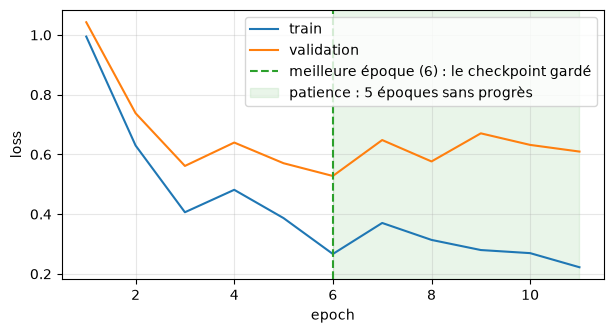

In [23]:
# La courbe de l'early stopping, comme sur la slide 13
e = range(1, len(history_es["val_loss"]) + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(e, history_es["train_loss"], label="train")
plt.plot(e, history_es["val_loss"], label="validation")
plt.axvline(best_epoch_es, color="C2", ls="--", label=f"meilleure époque ({best_epoch_es}) : le checkpoint gardé")
plt.axvspan(best_epoch_es, len(history_es["val_loss"]), color="C2", alpha=0.1, label="patience : 5 époques sans progrès")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

### TP · Exercice 11 : le tableau comparatif (livrable)

> **Énoncé** : construire un DataFrame pandas `results`, une ligne par run (`"baseline"`, `"weight decay"`, `"dropout"`, `"early stopping"`) et 3 colonnes : `"val_acc"` (la précision de validation du modèle **final** ; pour l'early stopping, le meilleur modèle rechargé, donc `history_es["val_acc"][best_epoch_es - 1]`), `"gap"` (précision d'entraînement moins précision de validation de **ce même** modèle), `"best_val_loss"` (la plus petite loss de validation du run).

🧩 **Le code ligne par ligne**

- `row(history, i)` : une petite fonction qui renvoie les 3 valeurs pour l'époque d'indice `i`. Pour les trois premiers runs, le modèle final est celui de la dernière époque : `i = -1`. Pour l'early stopping, c'est la meilleure époque : `i = best_epoch_es - 1` (les indices Python partent de 0, les époques de 1).
- `pd.DataFrame.from_dict({...}, orient="index", columns=[...])` : chaque **clé** du dictionnaire devient une **ligne** (`orient="index"`), chaque liste de 3 valeurs remplit les 3 colonnes nommées.

In [24]:
### START CODE HERE ###
def row(history, i):
    # les 3 valeurs du modèle de l'époque d'indice i (i = -1 : la dernière)
    return [history["val_acc"][i],                              # précision de validation
            history["train_acc"][i] - history["val_acc"][i],    # écart train - validation
            min(history["val_loss"])]                           # meilleure loss de validation du run


results = pd.DataFrame.from_dict(
    {
        "baseline": row(history_base, -1),
        "weight decay": row(history_wd, -1),
        "dropout": row(history_drop, -1),
        "early stopping": row(history_es, best_epoch_es - 1),   # le meilleur modèle, celui qu'on a rechargé
    },
    orient="index",
    columns=["val_acc", "gap", "best_val_loss"],
)
### END CODE HERE ###

assert results is not None and results.shape == (4, 3), "4 rows, 3 columns"
assert list(results.index) == ["baseline", "weight decay", "dropout", "early stopping"]
assert abs(results.loc["dropout", "gap"] - gap_drop) < 1e-9
assert abs(results.loc["early stopping", "val_acc"] - _va) < 1e-9, "early stopping: use the reloaded best epoch"
assert results.loc["baseline", "gap"] == results["gap"].max(), "the baseline should have the largest gap"
print(results.round(3))
print("Exercise validated!")

                val_acc    gap  best_val_loss
baseline          0.815  0.164          0.528
weight decay      0.789  0.096          0.536
dropout           0.768  0.068          0.601
early stopping    0.818  0.082          0.528
Exercise validated!


In [25]:
# Pour mieux lire le tableau : la précision d'entraînement et la loss de validation du modèle gardé
for name, h, i in [("baseline", history_base, -1), ("weight decay", history_wd, -1),
                   ("dropout", history_drop, -1), ("early stopping", history_es, best_epoch_es - 1)]:
    print(f"{name:15s} précision train {h['train_acc'][i]:.3f} | loss de validation du modèle gardé {h['val_loss'][i]:.3f} | "
          f"précision de validation entre {min(h['val_acc'][4:]):.3f} et {max(h['val_acc'][4:]):.3f} après l'époque 5")

baseline        précision train 0.979 | loss de validation du modèle gardé 0.839 | précision de validation entre 0.784 et 0.826 après l'époque 5
weight decay    précision train 0.885 | loss de validation du modèle gardé 0.615 | précision de validation entre 0.720 et 0.809 après l'époque 5
dropout         précision train 0.837 | loss de validation du modèle gardé 0.693 | précision de validation entre 0.735 et 0.810 après l'époque 5
early stopping  précision train 0.900 | loss de validation du modèle gardé 0.528 | précision de validation entre 0.784 et 0.818 après l'époque 5


💡 **Ce qu'on observe (le livrable).** Dans notre exécution :

| Run | `val_acc` | `gap` | `best_val_loss` |
|---|---|---|---|
| baseline | 0.815 | 0.164 | 0.528 |
| weight decay | 0.789 | 0.096 | 0.536 |
| dropout | 0.768 | 0.068 | 0.601 |
| early stopping | **0.818** | 0.082 | 0.528 |

**Comment lire ce tableau.** Chaque outil réduit l'écart entre entraînement et validation, mais par des chemins différents :

- le **weight decay** et le **dropout** rendent l'apprentissage par cœur plus **difficile** : la précision d'entraînement baisse (88.5 % et 83.7 % au lieu de 97.9 %) et la loss de validation ne s'envole plus (0.62 et 0.69 au lieu de 0.84) ;
- l'**early stopping** ne change pas l'entraînement : il garde simplement le modèle de la meilleure époque (la 6e). Ici c'est lui qui a la meilleure précision de validation, et c'est **gratuit**.

⚠️ **Deux pièges de lecture, très instructifs :**

1. **Un petit écart n'est pas le but en soi.** Le dropout a le plus petit écart, mais aussi la plus basse précision de validation : il a réduit l'écart surtout en **freinant l'apprentissage**. Avec ces réglages ($\lambda = 10^{-2}$, $p = 0.5$, SGD à pas constant pendant 30 époques), la régularisation est un peu trop forte pour le budget d'entraînement. Ce qui compte, c'est la performance sur la **validation** ; la force de la régularisation ($\lambda$, $p$) se règle, justement, en regardant la validation.
2. **Une seule époque est une mesure bruitée.** La dernière ligne de la cellule ci-dessus montre que, après l'époque 5, la précision de validation de chaque run varie de plusieurs points d'une époque à l'autre (le SGD à pas constant rebondit autour du minimum). Comparer des modèles sur **leur dernière époque** revient en partie à comparer du bruit. D'où l'intérêt de l'early stopping (garder la meilleure époque) et des schedules (partie D), qui calment la fin de l'entraînement.

Sur 2 000 images, aucun outil isolé ne fait de miracle : le vrai remède au surapprentissage reste **plus de données**. En combinant les outils correctement (batch norm, dropout, AdamW et un schedule), l'exercice bonus 23 dépasse bien la baseline.

---
## TP partie C : la normalisation par batch

### TP · Exercice 12 : la batch norm à la main

> **Énoncé** : écrire `batchnorm_forward(Z, gamma, beta, eps=1e-5)` pour un batch `Z` de forme `(m, n)` (m exemples, n neurones). Pour **chaque neurone** (chaque colonne) : $\mu_B$, $\sigma_B^2$ (divisée par $m$), $\hat z = (z - \mu_B)/\sqrt{\sigma_B^2 + \varepsilon}$, puis $y = \gamma \hat z + \beta$.

🧩 **Le code ligne par ligne**

| Ligne | Forme | Rôle |
|---|---|---|
| `mu = Z.mean(dim=0)` | `(n,)` | `dim=0` = on moyenne **le long des lignes** (les exemples) : une moyenne par neurone (par colonne) |
| `var = Z.var(dim=0, unbiased=False)` | `(n,)` | la variance divisée par $m$ ; par défaut (`unbiased=True`) PyTorch diviserait par $m - 1$ |
| `Z_hat = (Z - mu) / torch.sqrt(var + eps)` | `(m, n)` | le **broadcasting** : `mu` de forme `(n,)` est retiré de **chaque ligne** de `Z` |
| `Y = gamma * Z_hat + beta` | `(m, n)` | même broadcasting : chaque colonne a son $\gamma$ et son $\beta$ |

Les asserts comparent avec l'exercice du cours 3 (on attend $(-1.5, -0.167, -0.167, 3.833)$) et avec `nn.BatchNorm1d` en mode entraînement.

In [26]:
def batchnorm_forward(Z, gamma, beta, eps=1e-5):
    ### START CODE HERE ###
    mu = Z.mean(dim=0)                           # (n,) une moyenne par neurone (sur les m exemples)
    var = Z.var(dim=0, unbiased=False)           # (n,) variance divisée par m
    Z_hat = (Z - mu) / torch.sqrt(var + eps)     # (m, n) moyenne 0, variance 1 par colonne
    Y = gamma * Z_hat + beta                     # (m, n) échelle et décalage appris
    ### END CODE HERE ###
    return Y


_y = batchnorm_forward(torch.tensor([[1.0], [3.0], [3.0], [9.0]]), torch.tensor([2.0]), torch.tensor([0.5]))
assert _y is not None and torch.allclose(_y.flatten(), torch.tensor([-1.5, -1 / 6, -1 / 6, 23 / 6]), atol=1e-4), \
    f"course Exercise 3 expects (-1.5, -0.167, -0.167, 3.833), found {_y.flatten()}"
torch.manual_seed(0)
_Z = torch.randn(8, 3) * 4 + 2
_bn = nn.BatchNorm1d(3)
with torch.no_grad():
    _bn.weight.copy_(torch.tensor([1.0, 2.0, 0.5])); _bn.bias.copy_(torch.tensor([0.0, -1.0, 3.0]))
_bn.train()
assert torch.allclose(batchnorm_forward(_Z, _bn.weight.detach(), _bn.bias.detach()), _bn(_Z).detach(), atol=1e-5), \
    "your result differs from nn.BatchNorm1d: normalise each column, with the biased variance"
print("Exercise validated!")

Exercise validated!


### TP · Exercice 13 : les statistiques glissantes

> **Énoncé** : un `nn.BatchNorm1d(3)` neuf démarre avec `running_mean = 0` et `running_var = 1`. Après **un** passage en mode entraînement sur le batch `_Z` (8 exemples, 3 neurones), PyTorch les met à jour avec `momentum = 0.1`. Calculer `expected_mean` et `expected_var` (formes `(3,)`). Attention : pour la variance glissante, PyTorch utilise la variance **non biaisée** (divisée par $m - 1$).

🧩 **Le code ligne par ligne** : on applique les deux formules du cours (exercice du cours 3, question 4), colonne par colonne.

- `_Z.mean(dim=0)` : $\mu_B$ de chaque neurone.
- `_Z.var(dim=0, unbiased=True)` : la variance divisée par $m - 1 = 7$. C'est la seule différence avec l'exercice 12.
- `0.9 * ancienne_valeur + 0.1 * statistique_du_batch`, avec les valeurs de départ 0 (moyenne) et 1 (variance).

Pourquoi deux variances différentes ? Pour **normaliser le batch**, on utilise sa vraie dispersion ($1/m$). Pour **estimer la variance de toute la population** à partir d'un échantillon, la version $1/(m-1)$ est plus juste (elle corrige le fait que l'échantillon est centré sur sa propre moyenne).

In [27]:
### START CODE HERE ###
mu_B = _Z.mean(dim=0)                          # (3,) moyenne du batch, par neurone
var_B_unbiased = _Z.var(dim=0, unbiased=True)  # (3,) variance divisée par m - 1 = 7
expected_mean = 0.9 * torch.zeros(3) + 0.1 * mu_B            # départ : running_mean = 0
expected_var = 0.9 * torch.ones(3) + 0.1 * var_B_unbiased    # départ : running_var = 1
### END CODE HERE ###

_bn2 = nn.BatchNorm1d(3)
_bn2.train()
_ = _bn2(_Z)
assert expected_mean is not None and torch.allclose(expected_mean, _bn2.running_mean, atol=1e-5), "running mean differs"
assert expected_var is not None and torch.allclose(expected_var, _bn2.running_var, atol=1e-4), "running var differs (unbiased variance?)"
print("Exercise validated! In eval() mode, the layer normalises with these running statistics.")

Exercise validated! In eval() mode, the layer normalises with these running statistics.


### TP · Exercice 14 : la batch norm accélère l'entraînement

> **Énoncé** : écrire `make_bn_model()` : le grand réseau avec un `nn.BatchNorm1d(512)` entre chaque `Linear` caché et sa `ReLU`. Puis entraîner `make_big_model()` et `make_bn_model()` avec un **SGD simple** (`lr=0.01`, sans momentum) pendant `EPOCHS_SHORT` époques. Stocker `history_plain` et `history_bn`.

🧩 **Le code ligne par ligne**

- `nn.BatchNorm1d(512)` : le `512` est le **nombre de neurones** à normaliser (la sortie de la couche linéaire d'avant). Il a $2 \times 512$ paramètres appris ($\gamma$ et $\beta$) et deux statistiques glissantes.
- L'ordre Linear, BatchNorm1d, ReLU : on normalise les **pré-activations** $z$, puis on applique la ReLU.
- Pour une comparaison juste : `torch.manual_seed(0)` avant **chaque** modèle, même optimiseur (`SGD(lr=0.01)` sans momentum, volontairement « faible » pour bien voir la différence), même nombre d'époques.

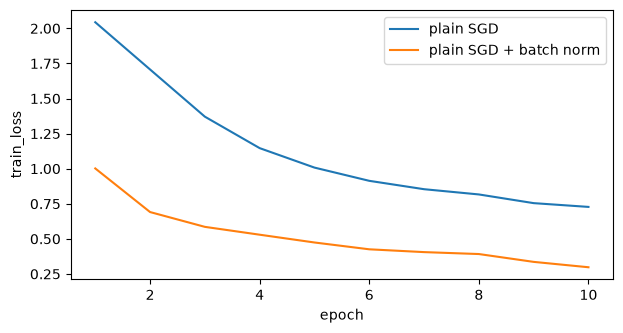

Exercise validated! Final train loss 0.728 without, 0.298 with batch norm.


In [28]:
def make_bn_model():
    ### START CODE HERE ###
    model = nn.Sequential(
        nn.Linear(784, 512), nn.BatchNorm1d(512), nn.ReLU(),    # normaliser z AVANT la ReLU
        nn.Linear(512, 512), nn.BatchNorm1d(512), nn.ReLU(),
        nn.Linear(512, 10),
    )
    ### END CODE HERE ###
    return model


### START CODE HERE ###
torch.manual_seed(0)
model_plain = make_big_model()
history_plain = fit(model_plain, torch.optim.SGD(model_plain.parameters(), lr=0.01), EPOCHS_SHORT)
torch.manual_seed(0)
model_bn = make_bn_model()
history_bn = fit(model_bn, torch.optim.SGD(model_bn.parameters(), lr=0.01), EPOCHS_SHORT)
### END CODE HERE ###

assert make_bn_model() is not None and sum(isinstance(l, nn.BatchNorm1d) for l in make_bn_model()) == 2
assert history_bn is not None and len(history_bn["train_loss"]) == EPOCHS_SHORT
assert history_bn["train_loss"][-1] < 0.8 * history_plain["train_loss"][-1], "batch norm should train clearly faster"
plot_compare({"plain SGD": history_plain, "plain SGD + batch norm": history_bn}, "train_loss")
print(f"Exercise validated! Final train loss {history_plain['train_loss'][-1]:.3f} without, "
      f"{history_bn['train_loss'][-1]:.3f} with batch norm.")

💡 **Ce qu'on observe.** Même optimiseur, même pas, mêmes poids de départ : après 10 époques, la loss d'entraînement vaut **0.728 sans** batch norm et **0.298 avec**, environ 2.4 fois plus bas. Chaque couche reçoit des entrées de moyenne 0 et de variance 1 quoi que fassent les couches d'avant, donc le même pas $\eta$ convient à toutes les couches, et aucune n'est freinée par des entrées trop petites ou trop grandes.

---
## TP partie D : les optimiseurs

### TP · Exercice 15 : un pas de momentum

> **Énoncé** : écrire `momentum_step(w, v, g, lr, beta)` qui renvoie le nouveau `(w, v)` avec la convention de PyTorch : $v \leftarrow \beta v + g$, puis $w \leftarrow w - \eta\, v$. Les asserts rejouent l'exercice du cours 4 (on attend 0.8 puis 0.46) et comparent 3 pas avec `torch.optim.SGD(momentum=0.9)`.

🧩 Deux lignes, **dans cet ordre** : d'abord la nouvelle vitesse (avec le nouveau gradient), puis le pas avec cette nouvelle vitesse. Inverser les deux lignes donnerait un pas avec l'ancienne vitesse : faux. La fonction marche aussi bien sur des nombres que sur des tenseurs (les opérations sont les mêmes).

In [29]:
def momentum_step(w, v, g, lr, beta):
    ### START CODE HERE ###
    v = beta * v + g        # 1. la vitesse : mémoire des gradients passés + le gradient actuel
    w = w - lr * v          # 2. le pas, avec la NOUVELLE vitesse
    ### END CODE HERE ###
    return w, v


_w, _v = 1.0, 0.0
_ws = []
for _ in range(2):
    _w, _v = momentum_step(_w, _v, 2 * _w, 0.1, 0.9)
    _ws.append(_w)
assert np.allclose(_ws, [0.8, 0.46]), f"course Exercise 4 expects 0.8 then 0.46, found {_ws}"
torch.manual_seed(0)
_p = torch.randn(4, requires_grad=True)
_opt = torch.optim.SGD([_p], lr=0.05, momentum=0.9)
_w, _v = _p.detach().clone(), torch.zeros(4)
for _ in range(3):
    _opt.zero_grad(); (_p ** 4).sum().backward(); _g = _p.grad.detach().clone(); _opt.step()
    _w, _v = momentum_step(_w, _v, _g, 0.05, 0.9)
assert torch.allclose(_w, _p.detach(), atol=1e-6), "3 steps should match torch.optim.SGD(momentum=0.9)"
print("Exercise validated!")

Exercise validated!


### TP · Exercice 16 : un pas d'Adam

> **Énoncé** : écrire `adam_step(w, m, s, g, t, lr, beta1=0.9, beta2=0.999, eps=1e-8)` qui renvoie le nouveau `(w, m, s)`. `t` est le numéro du pas, à partir de 1.

🧩 **Le code ligne par ligne** : les 5 formules du cours, dans l'ordre.

| Ligne | Rôle |
|---|---|
| `m = beta1 * m + (1 - beta1) * g` | moyenne glissante des gradients (la direction, avec momentum) |
| `s = beta2 * s + (1 - beta2) * g ** 2` | moyenne glissante des **carrés** (la taille typique du gradient) |
| `m_hat = m / (1 - beta1 ** t)` | correction du biais : sans elle, $m$ serait 10 fois trop petit au pas 1 |
| `s_hat = s / (1 - beta2 ** t)` | idem pour $s$ (1000 fois trop petit au pas 1) |
| `w = w - lr * m_hat / (torch.sqrt(s_hat) + eps)` | le pas : direction $\hat m$, divisée par la taille typique $\sqrt{\hat s}$ |

$\varepsilon = 10^{-8}$ évite une division par 0 si un gradient est nul depuis le début. Les asserts vérifient que le premier pas vaut $\eta$ (exercice du cours 4 : $1 \to 0.9$) et comparent 3 pas avec `torch.optim.Adam`.

In [30]:
def adam_step(w, m, s, g, t, lr, beta1=0.9, beta2=0.999, eps=1e-8):
    ### START CODE HERE ###
    m = beta1 * m + (1 - beta1) * g              # moyenne des gradients
    s = beta2 * s + (1 - beta2) * g ** 2         # moyenne des gradients au carré
    m_hat = m / (1 - beta1 ** t)                 # corrections du biais (m et s partent de 0)
    s_hat = s / (1 - beta2 ** t)
    w = w - lr * m_hat / (torch.sqrt(s_hat) + eps)   # un pas par paramètre
    ### END CODE HERE ###
    return w, m, s


_w1, _, _ = adam_step(torch.tensor([1.0]), torch.zeros(1), torch.zeros(1), torch.tensor([2.0]), 1, 0.1)
assert torch.allclose(_w1, torch.tensor([0.9])), f"first Adam step from w = 1 with lr 0.1 should give 0.9, found {_w1}"
torch.manual_seed(0)
_p = torch.randn(4, requires_grad=True)
_opt = torch.optim.Adam([_p], lr=0.01)
_w, _m, _s = _p.detach().clone(), torch.zeros(4), torch.zeros(4)
for _t in range(1, 4):
    _opt.zero_grad(); (_p ** 4).sum().backward(); _g = _p.grad.detach().clone(); _opt.step()
    _w, _m, _s = adam_step(_w, _m, _s, _g, _t, 0.01)
assert torch.allclose(_w, _p.detach(), atol=1e-6), "3 steps should match torch.optim.Adam"
print("Exercise validated!")

Exercise validated!


### TP · Exercice 17 : SGD contre momentum contre Adam

> **Énoncé** : entraîner trois fois le grand réseau pendant `EPOCHS_SHORT` époques, avec les mêmes poids initiaux (`torch.manual_seed(0)` avant chaque `make_big_model()`) : `"SGD"` (`lr=0.05`), `"momentum"` (`lr=0.05, momentum=0.9`), `"Adam"` (`lr=1e-3`, le réglage par défaut d'Adam). Stocker les trois historiques dans le dictionnaire `histories_opt`.

🧩 **Le code ligne par ligne**

- `optimiseurs` est un dictionnaire de **fonctions** : `lambda p: torch.optim.SGD(p, lr=0.05)` est une petite fonction anonyme qui, quand on lui donne des paramètres `p`, crée l'optimiseur. Pourquoi des fonctions et pas directement des optimiseurs ? Parce qu'un optimiseur est lié aux paramètres d'**un** modèle précis : il faut le créer **après** chaque nouveau modèle.
- La boucle : pour chaque nom, graine 0, modèle neuf, `make_opt(model.parameters())` crée l'optimiseur, `fit` entraîne, on range l'historique sous ce nom.

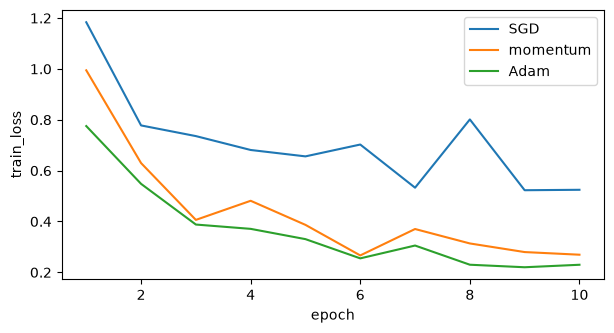

Exercise validated! {'SGD': 0.525, 'momentum': 0.269, 'Adam': 0.23}


In [31]:
### START CODE HERE ###
optimiseurs = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.05),
    "momentum": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "Adam": lambda p: torch.optim.Adam(p, lr=1e-3),
}
histories_opt = {}
for name, make_opt in optimiseurs.items():
    torch.manual_seed(0)                                  # mêmes poids initiaux pour les trois
    model = make_big_model()
    histories_opt[name] = fit(model, make_opt(model.parameters()), EPOCHS_SHORT)
### END CODE HERE ###

assert set(histories_opt) == {"SGD", "momentum", "Adam"}, "three keys: SGD, momentum, Adam"
_final = {k: h["train_loss"][-1] for k, h in histories_opt.items()}
assert _final["momentum"] < _final["SGD"] and _final["Adam"] < _final["SGD"], f"momentum and Adam should beat plain SGD: {_final}"
plot_compare(histories_opt, "train_loss")
print("Exercise validated!", {k: round(v, 3) for k, v in _final.items()})

💡 **Ce qu'on observe.** Après 10 époques, loss d'entraînement : **SGD simple 0.525, momentum 0.269, Adam 0.230**. Le momentum divise la loss par 2 avec le même pas $\eta = 0.05$ : la vitesse accumulée fait des pas jusqu'à 10 fois plus grands dans les directions constantes, et amortit le bruit des mini-batchs. Adam fait encore un peu mieux avec son réglage par défaut ($\eta = 10^{-3}$), sans qu'on ait eu à chercher le bon pas.

### TP · Exercice 18 : un schedule cosinus du pas d'apprentissage

> **Énoncé** : créer un modèle, un SGD avec `lr=0.05, momentum=0.9`, un scheduler cosinus avec `T_max=EPOCHS_SHORT`, et entraîner : `history_cos = fit(model, optimizer, EPOCHS_SHORT, scheduler=scheduler)`.

📖 **Les schedules (slide 22)** : de **grands pas au début** (avancer vite), de **petits pas à la fin** (se poser dans un minimum au lieu de rebondir autour). Image : on court vers la ville, puis on marche au pas pour trouver l'adresse exacte.

- **Step decay** : diviser $\eta$ par 10 toutes les quelques époques.
- **Cosinus** : une décroissance douce jusqu'à 0, le long d'une demi-période de cosinus : $\eta_t = \eta_0 \cdot \frac{1}{2}\big(1 + \cos(\pi t / T)\big)$, avec $t$ le nombre d'appels à `scheduler.step()`.
- **Warmup** : augmenter $\eta$ linéairement pendant les premiers pas (les statistiques d'Adam sont peu fiables au début) ; standard pour les transformers.

🧩 **Le code ligne par ligne**

- `CosineAnnealingLR(optimizer, T_max=EPOCHS_SHORT)` : le scheduler **modifie le `lr` de l'optimiseur** qu'on lui donne, de 0.05 jusqu'à 0 en `T_max` appels.
- `fit` appelle `scheduler.step()` **une fois par époque, après** les pas de l'optimiseur, et enregistre dans `history["lr"]` le pas utilisé à chaque époque.

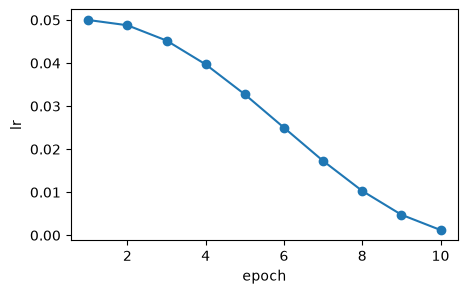

Exercise validated! Final train loss 0.165 with the schedule, 0.269 without.


In [32]:
torch.manual_seed(0)
### START CODE HERE ###
model_cos = make_big_model()
optimizer = torch.optim.SGD(model_cos.parameters(), lr=0.05, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_SHORT)   # 0.05 -> 0 en 10 époques
history_cos = fit(model_cos, optimizer, EPOCHS_SHORT, scheduler=scheduler)
### END CODE HERE ###

assert history_cos is not None and len(history_cos["lr"]) == EPOCHS_SHORT
assert abs(history_cos["lr"][0] - 0.05) < 1e-9, "the first epoch uses the initial learning rate"
assert all(a > b for a, b in zip(history_cos["lr"], history_cos["lr"][1:])), "the learning rate must decrease"
assert history_cos["lr"][-1] < 0.01, "at the last epoch the learning rate should be small"
plt.figure(figsize=(5, 3)); plt.plot(range(1, EPOCHS_SHORT + 1), history_cos["lr"], "o-"); plt.xlabel("epoch"); plt.ylabel("lr"); plt.show()
print(f"Exercise validated! Final train loss {history_cos['train_loss'][-1]:.3f} with the schedule, "
      f"{histories_opt['momentum']['train_loss'][-1]:.3f} without.")

In [33]:
# Le pas de chaque époque, comparé à la formule du cosinus
for t, lr_t in enumerate(history_cos["lr"]):
    formule = 0.05 * 0.5 * (1 + math.cos(math.pi * t / EPOCHS_SHORT))
    print(f"époque {t + 1:2d} : lr = {lr_t:.5f}   formule {formule:.5f}")

époque  1 : lr = 0.05000   formule 0.05000
époque  2 : lr = 0.04878   formule 0.04878
époque  3 : lr = 0.04523   formule 0.04523
époque  4 : lr = 0.03969   formule 0.03969
époque  5 : lr = 0.03273   formule 0.03273
époque  6 : lr = 0.02500   formule 0.02500
époque  7 : lr = 0.01727   formule 0.01727
époque  8 : lr = 0.01031   formule 0.01031
époque  9 : lr = 0.00477   formule 0.00477
époque 10 : lr = 0.00122   formule 0.00122


💡 **Ce qu'on observe.** Les pas suivent exactement la formule : 0.05 à la 1re époque, 0.025 à mi-parcours (6e époque), 0.0012 à la dernière. Avec le schedule, la loss d'entraînement finale vaut **0.165**, contre 0.269 avec le même optimiseur à pas constant (exercice 17). Les dernières époques, à petits pas, posent les poids au fond du minimum au lieu de rebondir autour.

---
## TP partie E : le docteur de l'entraînement

Trois collègues t'envoient leurs entraînements malades. Pour chacun : on exécute la cellule, on lit les chiffres, on pose le **diagnostic** (ce qui ne va pas, et comment on le sait), puis on soigne. On s'appuie sur le tableau de la slide 23 (exercice du cours 5).

### Patient 1

In [34]:
torch.manual_seed(0)
model = make_big_model()
optimizer = torch.optim.SGD(model.parameters(), lr=1.0, momentum=0.9)
history_p1 = fit(model, optimizer, 3, verbose=True)

epoch  1  train loss nan  val loss nan  val acc 0.093


epoch  2  train loss nan  val loss nan  val acc 0.093


epoch  3  train loss nan  val loss nan  val acc 0.093


### TP · Exercice 19 : diagnostiquer et soigner le patient 1

**Le diagnostic** : la loss vaut `nan` dès la première époque, et la précision de validation reste à 9.3 % (le réseau prédit toujours la même classe). C'est la première ligne du tableau de la slide 23 : **un pas d'apprentissage beaucoup trop grand**. Avec $\eta = 1.0$ et un momentum de 0.9, les pas effectifs peuvent atteindre $\eta/(1 - \beta) = 10$ fois le gradient : chaque mise à jour envoie les poids plus loin, les logits débordent, et la loss devient `nan` (le résultat d'un calcul impossible comme $\infty - \infty$). Une fois un seul poids à `nan`, tout ce qui en dépend devient `nan` : l'entraînement est perdu, il faut recommencer.

**Le soin** : même modèle, même type d'optimiseur, un pas qui marche. Le premier réflexe est de diviser $\eta$ par 10 ou plus ; on prend $\eta = 0.05$, la valeur qui marchait à l'exercice 2. On stocke l'historique dans `history_fix1` (`EPOCHS_SHORT` époques).

In [35]:
torch.manual_seed(0)
model = make_big_model()
### START CODE HERE ###
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)   # lr divisé par 20
history_fix1 = fit(model, optimizer, EPOCHS_SHORT)
### END CODE HERE ###

assert history_fix1 is not None and all(math.isfinite(v) for v in history_fix1["train_loss"]), "the loss must stay finite"
assert history_fix1["val_acc"][-1] > 0.7, f"validation accuracy should exceed 0.7, found {history_fix1['val_acc'][-1]:.3f}"
print("Exercise validated! Patient 1 cured:", round(history_fix1["val_acc"][-1], 3))

Exercise validated! Patient 1 cured: 0.784


In [36]:
# Bonus : balayer le pas d'apprentissage (3 époques chacun) pour voir où est la frontière
for lr_test in [1.0, 0.3, 0.1, 0.05, 0.01, 0.001]:
    torch.manual_seed(0)
    m_test = make_big_model()
    h = fit(m_test, torch.optim.SGD(m_test.parameters(), lr=lr_test, momentum=0.9), 3)
    print(f"lr = {lr_test:<6} train loss après 3 époques : {h['train_loss'][-1]:10.4f} | val acc {h['val_acc'][-1]:.3f}")

lr = 1.0    train loss après 3 époques :        nan | val acc 0.093


lr = 0.3    train loss après 3 époques :        nan | val acc 0.093


lr = 0.1    train loss après 3 époques :     0.4612 | val acc 0.781


lr = 0.05   train loss après 3 époques :     0.4062 | val acc 0.797


lr = 0.01   train loss après 3 époques :     0.5977 | val acc 0.756


lr = 0.001  train loss après 3 époques :     1.5067 | val acc 0.534


💡 Le balayage montre où est la frontière : avec un momentum de 0.9, $\eta = 1.0$ et $\eta = 0.3$ divergent (`nan`), $\eta = 0.1$ marche déjà, $\eta = 0.05$ est le meilleur sur 3 époques, et les pas trop petits apprennent beaucoup trop lentement ($\eta = 0.001$ : loss encore à 1.51 après 3 époques, c'est le sous-apprentissage du run D). Le bon pas est souvent un peu en dessous de celui qui diverge.

### Patient 2

Ce collègue a écrit sa propre époque d'entraînement. Le pas d'apprentissage est celui qui marche.

In [37]:
def buggy_train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()


torch.manual_seed(0)
model = make_big_model()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
history_p2 = fit(model, optimizer, 3, train_epoch_fn=buggy_train_one_epoch, verbose=True)

epoch  1  train loss 1408.776  val loss 1262.172  val acc 0.188


epoch  2  train loss nan  val loss nan  val acc 0.093


epoch  3  train loss nan  val loss nan  val acc 0.093


### TP · Exercice 20 : diagnostiquer et soigner le patient 2

**Le diagnostic** : la loss explose dès la première époque (1 409 en entraînement, 1 262 en validation), puis devient `nan`. Pourtant le pas est celui qui marche ($\eta = 0.05$) : le problème n'est pas un réglage, c'est un **bug dans la boucle**. Il manque **`optimizer.zero_grad()`**.

Pourquoi c'est grave : en PyTorch, `loss.backward()` **ajoute** les nouveaux gradients à ceux déjà stockés dans `p.grad`, il ne les remplace pas. Sans remise à zéro, après $k$ batchs, `p.grad` contient la **somme** des $k$ derniers gradients : le pas grossit à chaque batch (jusqu'à 32 fois le gradient en fin de première époque), et le momentum en rajoute. Les poids explosent. Même symptôme que le patient 1, cause différente : d'où l'intérêt de **relire la boucle** avant de toucher au pas.

**Le soin** : écrire `fixed_train_one_epoch` avec les **5 lignes** de la boucle d'entraînement, puis entraîner un modèle neuf avec elle pendant `EPOCHS_SHORT` époques.

🧩 **Les 5 lignes, dans l'ordre** (à connaître par cœur) :

| # | Ligne | Rôle |
|---|---|---|
| 1 | `optimizer.zero_grad()` | **effacer** les gradients du batch précédent (la ligne oubliée) |
| 2 | `logits = model(xb)` | forward |
| 3 | `loss = loss_fn(logits, yb)` | la loss du batch |
| 4 | `loss.backward()` | backward : remplit `p.grad` pour chaque paramètre (en **ajoutant** à ce qui s'y trouve) |
| 5 | `optimizer.step()` | la mise à jour des poids |

In [38]:
def fixed_train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for xb, yb in loader:
        ### START CODE HERE ###
        optimizer.zero_grad()            # 1. effacer les gradients du batch précédent
        logits = model(xb)               # 2. forward
        loss = loss_fn(logits, yb)       # 3. loss
        loss.backward()                  # 4. backward
        optimizer.step()                 # 5. mise à jour
        ### END CODE HERE ###


torch.manual_seed(0)
model = make_big_model()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
### START CODE HERE ###
history_fix2 = fit(model, optimizer, EPOCHS_SHORT, train_epoch_fn=fixed_train_one_epoch)
### END CODE HERE ###

assert history_fix2 is not None and all(math.isfinite(v) for v in history_fix2["train_loss"]), "the loss must stay finite"
assert history_fix2["val_acc"][-1] > 0.7, f"validation accuracy should exceed 0.7, found {history_fix2['val_acc'][-1]:.3f}"
print("Exercise validated! Patient 2 cured:", round(history_fix2["val_acc"][-1], 3))

Exercise validated! Patient 2 cured: 0.784


### Patient 3

Ce collègue voulait un réseau profond : 8 couches cachées de 128 neurones sigmoïdes.

In [39]:
def make_deep_sigmoid():
    layers, n_in = [], 784
    for _ in range(8):
        layers += [nn.Linear(n_in, 128), nn.Sigmoid()]
        n_in = 128
    return nn.Sequential(*layers, nn.Linear(n_in, 10))


torch.manual_seed(0)
model = make_deep_sigmoid()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
history_p3 = fit(model, optimizer, 3, verbose=True)
print("ln(10) =", round(math.log(10), 3))

epoch  1  train loss 2.367  val loss 2.351  val acc 0.105


epoch  2  train loss 2.362  val loss 2.371  val acc 0.100
epoch  3  train loss 2.319  val loss 2.332  val acc 0.105
ln(10) = 2.303


### TP · Exercice 21 : diagnostiquer et soigner le patient 3

**Le diagnostic** : la loss reste collée entre 2.32 et 2.37, c'est-à-dire autour de $\ln 10 \approx 2.30$, et la précision autour de 10 % : le réseau **n'apprend rien de l'image** (deuxième ligne du tableau de la slide 23). Le pas est correct et la boucle aussi (c'est le `fit` du TP). La cause est l'architecture : c'est le **vanishing gradient** de la session 5. Avec 8 couches sigmoïdes, la backpropagation multiplie le gradient par $\sigma' \le 1/4$ (et par des poids petits) à chaque couche : les premières couches ne reçoivent presque rien, leurs sorties restent aléatoires, et les dernières n'ont rien d'utile à apprendre. Remède : **ReLU** (dérivée 1 sur les chemins actifs) et **initialisation de He**.

**Le soin** : écrire `make_deep_fixed()` : les mêmes 8 couches cachées de 128 neurones, mais avec `nn.ReLU()`, et l'**initialisation de He** de chaque `nn.Linear` (`nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` et `nn.init.zeros_(layer.bias)`). Puis l'entraîner avec le même optimiseur pendant `EPOCHS_SHORT` époques.

🧩 **Le code ligne par ligne**

- On construit la liste des couches comme dans `make_deep_sigmoid`, en remplaçant `nn.Sigmoid()` par `nn.ReLU()` : dérivée 1 sur les chemins actifs, le gradient ne fond plus.
- `for layer in model.modules(): if isinstance(layer, nn.Linear):` : on parcourt les 9 couches linéaires.
- `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` : des poids de variance $2/n_\text{in}$, qui gardent la taille du signal constante à travers les couches ReLU (session 5). Le `_` final : le tenseur est rempli **en place**.
- `nn.init.zeros_(layer.bias)` : biais à 0.

In [40]:
def make_deep_fixed():
    ### START CODE HERE ###
    layers, n_in = [], 784
    for _ in range(8):
        layers += [nn.Linear(n_in, 128), nn.ReLU()]                   # ReLU au lieu de sigmoïde
        n_in = 128
    model = nn.Sequential(*layers, nn.Linear(n_in, 10))
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")  # He : variance 2 / n_in
            nn.init.zeros_(layer.bias)
    ### END CODE HERE ###
    return model


torch.manual_seed(0)
model = make_deep_fixed()
assert model is not None and sum(isinstance(l, nn.Linear) for l in model) == 9, "8 hidden layers + 1 output layer"
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
### START CODE HERE ###
history_fix3 = fit(model, optimizer, EPOCHS_SHORT)
### END CODE HERE ###

assert history_fix3 is not None and history_fix3["train_loss"][-1] < 1.2, "the loss should leave ln(10) = 2.30"
assert history_fix3["val_acc"][-1] > 0.55, f"validation accuracy should exceed 0.55, found {history_fix3['val_acc'][-1]:.3f}"
print("Exercise validated! Patient 3 cured:", round(history_fix3["val_acc"][-1], 3))

Exercise validated! Patient 3 cured: 0.738


💡 Avec ReLU et He, le même réseau à 8 couches apprend : **73.8 %** de précision de validation en 10 époques, au lieu de 10 %. Il reste moins bon que le grand réseau à 2 couches (78 %) : 8 couches étroites de 128 neurones sont plus dures à entraîner, et cette profondeur n'est pas utile pour ce problème. Mais il **apprend**, et c'est ce qu'on cherchait.

### TP · Exercice 22 : le gradient clipping

> **Énoncé** : après `loss.backward()`, calculer à la main la norme du gradient **complet** (tous les paramètres ensemble), $\lVert g \rVert = \sqrt{\sum_\text{param}\sum_\text{cases} g^2}$, et la stocker dans `total_norm` (un float Python). Puis `clip_grad_norm_(model.parameters(), max_norm=1.0)` renvoie la norme avant découpage et raccourcit les gradients en place si elle dépasse 1.

🧩 **Le code ligne par ligne**, de l'intérieur vers l'extérieur :

- `(p.grad ** 2).sum()` : la somme des carrés des cases du gradient d'**un** paramètre (une matrice de poids ou un vecteur de biais) ;
- `sum(... for p in model.parameters())` : on additionne sur **tous** les paramètres (6 tenseurs ici) : c'est la norme d'un seul grand vecteur qui contiendrait tous les gradients bout à bout ;
- `float(...)` puis `math.sqrt(...)` : la racine, en nombre Python.

La loss est multipliée par 50 exprès pour avoir de grands gradients. Après `clip_grad_norm_`, la norme doit valoir exactement 1 : la **direction** est gardée, seule la **longueur** est limitée (comme l'exemple $(3, 4) \to (0.6, 0.8)$ de la slide 24).

In [41]:
torch.manual_seed(0)
model = make_big_model()
loss = loss_fn(model(X_train[:256]), y_train[:256]) * 50      # a loss scaled up on purpose: large gradients
loss.backward()
### START CODE HERE ###
total_norm = math.sqrt(float(sum((p.grad ** 2).sum() for p in model.parameters())))   # norme du gradient complet
### END CODE HERE ###
returned = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
new_norm = math.sqrt(float(sum((p.grad ** 2).sum() for p in model.parameters())))

assert total_norm is not None and abs(total_norm - float(returned)) < 1e-3 * total_norm, "your norm differs from PyTorch's"
assert total_norm > 1.0, "the gradient norm should be larger than 1 here"
assert abs(new_norm - 1.0) < 1e-3, "after clipping, the norm should be exactly max_norm = 1"
print(f"Exercise validated! Norm {total_norm:.2f} before clipping, {new_norm:.3f} after.")

Exercise validated! Norm 51.02 before clipping, 1.000 after.


In [42]:
# L'exemple de la slide 24, à la main
g_ex = torch.tensor([3.0, 4.0])
c = 1.0
norme = g_ex.norm()
print(f"g = {g_ex.tolist()}, ||g|| = {norme.item()} > c = {c}, donc g <- c g / ||g|| = {(c * g_ex / norme).tolist()}")

g = [3.0, 4.0], ||g|| = 5.0 > c = 1.0, donc g <- c g / ||g|| = [0.6000000238418579, 0.800000011920929]


---
## TP bonus : ton meilleur modèle

### TP · Exercice 23 (bonus)

> **Énoncé** : combiner ce qu'on a appris (batch norm, dropout, AdamW, un schedule cosinus, early stopping...) pour construire `model_best`, l'entraîner sur les mêmes 2 000 images, et faire en sorte que la précision de validation du modèle final, `best_val_acc`, dépasse d'au moins 0.005 celle de la baseline finale (exercice 2).

📖 **Nos choix, et pourquoi**

| Choix | Pourquoi |
|---|---|
| `nn.Dropout(0.2)` **sur l'entrée** (avant la 1re couche) | éteindre 20 % des pixels au hasard : le réseau ne peut pas mémoriser une image pixel par pixel, c'est comme lui montrer des versions un peu abîmées de chaque image |
| `Linear`, `BatchNorm1d`, `ReLU`, `Dropout(0.5)` pour chaque couche cachée | batch norm : entraînement rapide et stable ; dropout 0.5 : la régularisation la plus efficace de la partie B |
| `AdamW(lr=1e-3, weight_decay=1e-2)` | Adam (pas adapté à chaque paramètre) avec un weight decay « découplé », appliqué directement aux poids plutôt que mélangé aux moyennes d'Adam |
| `CosineAnnealingLR` sur 20 époques | de grands pas au début, de petits à la fin pour se poser |

🧩 **Le code ligne par ligne**

- `n_epochs_best = 2 * EPOCHS_SHORT` : 20 époques (12 en mode `FAST_RUN`).
- `model_best = nn.Sequential(...)` : l'architecture du tableau ci-dessus.
- `optimizer = torch.optim.AdamW(...)` puis `scheduler = CosineAnnealingLR(optimizer, T_max=n_epochs_best)`.
- `history_best = fit(model_best, optimizer, n_epochs_best, scheduler=scheduler)`.
- `best_val_acc = evaluate(model_best, val_loader, loss_fn)[1]` : `evaluate` renvoie `(loss, précision)`, l'indice `[1]` prend la précision. L'assert recalcule exactement cette valeur.

In [43]:
torch.manual_seed(0)
### START CODE HERE ###
n_epochs_best = 2 * EPOCHS_SHORT
model_best = nn.Sequential(
    nn.Dropout(0.2),                                                  # éteindre 20 % des pixels d'entrée
    nn.Linear(784, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(512, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(512, 10),
)
optimizer = torch.optim.AdamW(model_best.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs_best)
history_best = fit(model_best, optimizer, n_epochs_best, scheduler=scheduler)
best_val_acc = evaluate(model_best, val_loader, loss_fn)[1]           # précision de validation du modèle final
### END CODE HERE ###

assert best_val_acc is not None and abs(best_val_acc - evaluate(model_best, val_loader, loss_fn)[1]) < 1e-9, \
    "best_val_acc must be the validation accuracy of the final model_best"
assert best_val_acc > history_base["val_acc"][-1] + 0.005, \
    f"{best_val_acc:.3f} does not beat the final baseline ({history_base['val_acc'][-1]:.3f}) by 0.005"
print(f"Exercise validated! {best_val_acc:.3f} versus {history_base['val_acc'][-1]:.3f} for the final baseline.")

Exercise validated! 0.834 versus 0.815 for the final baseline.


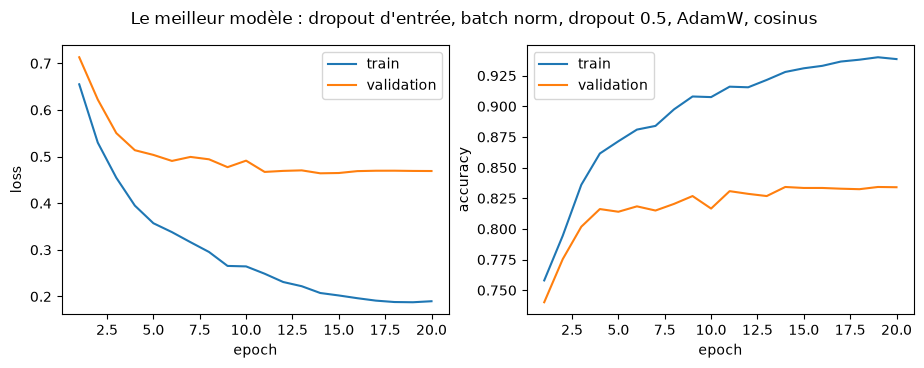

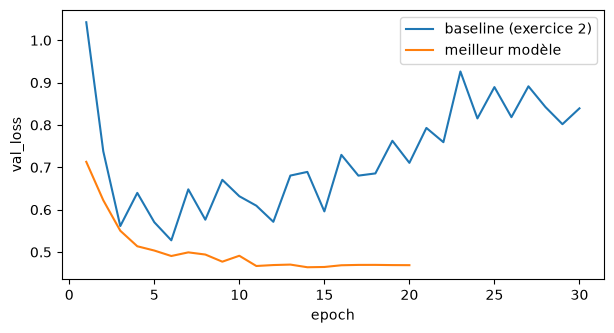

In [44]:
plot_history(history_best, "Le meilleur modèle : dropout d'entrée, batch norm, dropout 0.5, AdamW, cosinus")
plot_compare({"baseline (exercice 2)": history_base, "meilleur modèle": history_best}, "val_loss")

💡 **Ce qu'on observe.** Le meilleur modèle atteint **0.834** de précision de validation, contre 0.815 pour la baseline (+1.9 point). Et surtout, regarde les courbes : sa loss de validation **ne remonte plus** en fin d'entraînement (0.469 à la fin, contre 0.839 pour la baseline). L'écart entre entraînement et validation reste présent (2 000 images, c'est peu), mais le réseau n'est plus trop sûr de lui. Chaque outil apporte sa pièce : le dropout et le weight decay limitent l'apprentissage par cœur, la batch norm et Adam compensent la difficulté ajoutée en accélérant l'entraînement, et le schedule cosinus calme les dernières époques.

---
# 📝 Livrables et fiche résumé de la session 6

In [45]:
print("LIVRABLES DU TP06")
print("\nTableau comparatif de la partie B (exercice 11) :")
print(results.round(3))
print(f"\nBatch norm (exercice 14) : train loss {history_plain['train_loss'][-1]:.3f} sans, {history_bn['train_loss'][-1]:.3f} avec")
print("Optimiseurs (exercice 17), train loss finale :", {k: round(h["train_loss"][-1], 3) for k, h in histories_opt.items()})
print(f"Patients soignés : 1 -> {history_fix1['val_acc'][-1]:.3f}, 2 -> {history_fix2['val_acc'][-1]:.3f}, "
      f"3 -> {history_fix3['val_acc'][-1]:.3f} de précision de validation")
print(f"Bonus : meilleur modèle {best_val_acc:.3f} contre {history_base['val_acc'][-1]:.3f} pour la baseline")

LIVRABLES DU TP06

Tableau comparatif de la partie B (exercice 11) :
                val_acc    gap  best_val_loss
baseline          0.815  0.164          0.528
weight decay      0.789  0.096          0.536
dropout           0.768  0.068          0.601
early stopping    0.818  0.082          0.528

Batch norm (exercice 14) : train loss 0.728 sans, 0.298 avec
Optimiseurs (exercice 17), train loss finale : {'SGD': 0.525, 'momentum': 0.269, 'Adam': 0.23}
Patients soignés : 1 -> 0.784, 2 -> 0.784, 3 -> 0.738 de précision de validation
Bonus : meilleur modèle 0.834 contre 0.815 pour la baseline


| Notion | Formule ou code | En une phrase |
|---|---|---|
| Surapprentissage | train loss qui baisse, validation qui remonte | le réseau apprend par cœur ; **toujours tracer les deux courbes** |
| Weight decay (L2) | $w \leftarrow (1 - \eta\lambda)\,w - \eta\,g$ ; `SGD(..., weight_decay=λ)`, `AdamW` | un élastique qui ramène les poids vers 0 |
| Dropout | $\tilde a = m \odot a / (1 - p)$ ; `nn.Dropout(p)` | éteindre des neurones au hasard à l'entraînement, rien au test |
| Early stopping | `copy.deepcopy(model.state_dict())`, `load_state_dict` | garder le checkpoint de la meilleure époque de validation |
| Batch norm | $\hat z = (z - \mu_B)/\sqrt{\sigma_B^2 + \varepsilon}$, $y = \gamma\hat z + \beta$ ; `nn.BatchNorm1d` | chaque neurone normalisé sur le batch ; statistiques glissantes au test |
| Layer norm | mêmes formules, sur les caractéristiques d'un exemple | indépendante du batch : le standard des transformers |
| Momentum | $v \leftarrow \beta v + g$, $w \leftarrow w - \eta v$ | une bille qui prend de l'élan et amortit les zigzags |
| Adam | $\hat m / (\sqrt{\hat s} + \varepsilon)$, avec correction du biais | un pas sur mesure par paramètre ; le premier pas vaut $\eta$ |
| Schedule | `CosineAnnealingLR`, `scheduler.step()` une fois par époque | grands pas au début, petits à la fin |
| Gradient clipping | $g \leftarrow c\,g/\lVert g\rVert$ si $\lVert g\rVert > c$ ; `clip_grad_norm_` | garder la direction, limiter la longueur |
| Diagnostic | `nan` : $\eta$ trop grand ; plat à $\ln C$ : rien n'est appris | lire les courbes avant de toucher au code |
| La boucle | `zero_grad`, forward, loss, `backward`, `step` | oublier `zero_grad` additionne les gradients de tous les batchs |

**Projet** (slide 29) : ajouter à ton dépôt les courbes de suivi entraînement / validation et une section de diagnostic des échecs (tag `m2`).

**Prochaine session** : les images ont une structure. Les réseaux de neurones convolutifs.